In [563]:
import numpy as np
import pandas as pd

from sklearn.datasets import (load_diabetes,load_breast_cancer,load_digits,load_iris)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error,r2_score,accuracy_score,confusion_matrix,precision_recall_fscore_support)

In [564]:
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

breast_cancer = load_breast_cancer()
X_breast = breast_cancer.data
y_breast = 1 - breast_cancer.target

digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target

iris = load_iris()
X_iris = iris.data
y_iris = iris.target


In [565]:
def split_dataset(X, y, classification=True):

    #20% for testing
    stratify_value = y if classification else None
    
    X_temp, X_test, y_temp, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value)


    #25% of the remaining 80% for validation
    stratify_value = y_temp if classification else None

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp,
        y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_value)

    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes_split = split_dataset(X_diabetes, y_diabetes, classification=False)
breast_split = split_dataset(X_breast, y_breast)
digits_split = split_dataset(X_digits, y_digits)
iris_split = split_dataset(X_iris, y_iris)


In [566]:
datasets = {
    "Diabetes": diabetes_split,
    "Breast Cancer": breast_split,
    "Digits": digits_split,
    "Iris": iris_split
}

for name, split in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split

    print("\n", name)

    print("Training size:", len(X_train))
    print("Validation size:", len(X_val))
    print("Testing size:", len(X_test))
    print("Total size:", len(X_train) + len(X_val) + len(X_test))

    if name != "Diabetes":
        print("\nTraining class counts:",
              np.unique(y_train, return_counts=True))

        print("Validation class counts:",
              np.unique(y_val, return_counts=True))

        print("Testing class counts:",
              np.unique(y_test, return_counts=True))




 Diabetes
Training size: 264
Validation size: 89
Testing size: 89
Total size: 442

 Breast Cancer
Training size: 341
Validation size: 114
Testing size: 114
Total size: 569

Training class counts: (array([0, 1]), array([214, 127]))
Validation class counts: (array([0, 1]), array([71, 43]))
Testing class counts: (array([0, 1]), array([72, 42]))

 Digits
Training size: 1077
Validation size: 360
Testing size: 360
Total size: 1797

Training class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Testing class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

 Iris
Training size: 90
Validation size: 30
Testing size: 30
Total size: 150

Training class counts: (array([0, 1, 2]), array([30, 30, 30]))
Validation class counts: (array([0, 1, 2]), array([10, 10, 10]))
Testing class c

In [567]:
class Standardizer:

    def fit(self, X):
        self.mean = np.mean(X, axis=0) #axis=0 means calculate the mean vertically, column by column.
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1  #avoid devision by 0
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

    

In [568]:
def add_bias(X):
        # Add a column of ones at the beginning
        return np.column_stack((np.ones(X.shape[0]), X))

In [569]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

print("Training means:")
print(np.mean(X_train_std, axis=0))

print("\nTraining standard deviations:")
print(np.std(X_train_std, axis=0))

X_train_bias = add_bias(X_train_std)

print("\nShape before adding bias:", X_train_std.shape)
print("Shape after adding bias:", X_train_bias.shape)


Training means:
[-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03877319e-15 -5.53100810e-16]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Shape before adding bias: (264, 10)
Shape after adding bias: (264, 11)


We must calculate the mean and standard deviation using only the training data to prevent data leakage and ensure that validation and test data remain unseen during training. If we calculate them using all rows, information from the test data influences preprocessing, making the evaluation misleading because the model has indirectly used information from the test set.

In [570]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_total)

In [571]:
def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int) #k is number of classes
    np.add.at(cm, (y, pred), 1)
    return cm

In [572]:
def accuracy(y, pred):
    return np.mean(y == pred)


def classification_metrics(cm):

    tp = np.diag(cm)
    fp = np.sum(cm, axis=0) - tp
    fn = np.sum(cm, axis=1) - tp


    # precision = 0 if a class is never predicted
    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) != 0
    )

    recall = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fn) != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }

In [573]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)

np.random.seed(42)

y_reg = np.random.randn(500)
pred_reg = np.random.randn(500)

K = 4
N = 500

y = np.random.randint(0, K, N)
pred = np.random.randint(0, K, N)

In [574]:
assert np.isclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12
)

assert np.isclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12
)

assert np.isclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12
)


In [575]:
# Confusion matrix
cm = confusion_matrix(y, pred, K)

cm_sklearn = sklearn_confusion_matrix(
    y, pred, labels=np.arange(K)
)

assert np.array_equal(cm, cm_sklearn)


# Accuracy
assert np.isclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12
)


# Precision, recall and F1
my_metrics = classification_metrics(cm)

p_sklearn, r_sklearn, f1_sklearn, _ = precision_recall_fscore_support(
    y,
    pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)


# Compare individual classes
assert np.allclose(
    my_metrics["precision"], p_sklearn, atol=1e-12
)

assert np.allclose(
    my_metrics["recall"], r_sklearn, atol=1e-12
)

assert np.allclose(
    my_metrics["f1"], f1_sklearn, atol=1e-12
)


# Compare macro averages
assert np.isclose(
    my_metrics["macro_precision"],
    np.mean(p_sklearn),
    atol=1e-12
)

assert np.isclose(
    my_metrics["macro_recall"],
    np.mean(r_sklearn),
    atol=1e-12
)

assert np.isclose(
    my_metrics["macro_f1"],
    np.mean(f1_sklearn),
    atol=1e-12
)

print("All metrics match sklearn!")

All metrics match sklearn!


In [576]:
def grad_check(f, grad, w):
    epsilon = 1e-5
    numerical_grad = np.zeros_like(w, dtype=float)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += epsilon
        w_minus[i] -= epsilon

        numerical_grad[i] = (
            f(w_plus) - f(w_minus)
        ) / (2 * epsilon)

    analytical_grad = grad(w)

    numerator = np.linalg.norm(
        analytical_grad - numerical_grad
    )

    denominator = max(
        np.linalg.norm(analytical_grad),
        np.linalg.norm(numerical_grad),
        1e-12
    )

    return numerator / denominator

In [577]:

def f(w):
    return np.sum(w ** 2)

def grad(w):
    return 2 * w

w = np.array([2.0, 3.0, 4.0])
error = grad_check(f, grad, w)
print("Relative error:", error)

Relative error: 1.6811399006819465e-11


///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////

In [578]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

# Standardize using training data only
scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

# Add bias column
X_train_bias = add_bias(X_train_std)
X_val_bias = add_bias(X_val_std)
X_test_bias = add_bias(X_test_std)

J(w) = (1 / 2N) (X̃w - y)ᵀ(X̃w - y)
J(w) = (1 / 2N) (wᵀX̃ᵀX̃w - 2yᵀX̃w + yᵀy)
∇J(w) = (1 / 2N) (2X̃ᵀX̃w - 2X̃ᵀy)
∇J(w) = (1 / N) (X̃ᵀX̃w - X̃ᵀy)

Set the gradient equal to zero:
(1 / N) (X̃ᵀX̃w - X̃ᵀy) = 0
X̃ᵀX̃w - X̃ᵀy = 0
X̃ᵀX̃w = X̃ᵀy

Multiply both sides by (X̃ᵀX̃)⁻¹:
w* = (X̃ᵀX̃)⁻¹ X̃ᵀy

In [579]:
def normal_equation(X, y):

    a = X.T @ X
    b = X.T @ y

    w = np.linalg.solve(a, b)  #solve the equatiom aw=b
    return w

w_star = normal_equation(X_train_bias, y_train)
print("Optimal weights:")
print(w_star)

Optimal weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]


In [580]:
# Predictions
y_train_pred = X_train_bias @ w_star
y_val_pred = X_val_bias @ w_star
y_test_pred = X_test_bias @ w_star

results = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "RMSE": [
        rmse(y_train, y_train_pred),
        rmse(y_val, y_val_pred),
        rmse(y_test, y_test_pred)
    ]
})

print(results)

print("\nTest R2:", r2(y_test, y_test_pred))

condition_number = np.linalg.cond(X_train_bias.T @ X_train_bias)
print("\nCondition number:", condition_number)

      Dataset       RMSE
0       Train  54.610364
1  Validation  51.193714
2        Test  54.156413

Test R2: 0.4464263764021128

Condition number: 505.70612269609745


In [581]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_std, y_train)

# Combine sklearn intercept and coefficients
w_sklearn = np.concatenate((
    [linear_model.intercept_],
    linear_model.coef_
))

print("Our weights:")
print(w_star)

print("\nSklearn weights:")
print(w_sklearn)

print("\nMaximum absolute difference:",
      np.max(np.abs(w_star - w_sklearn)))

assert np.allclose(w_star, w_sklearn, atol=1e-6)


Our weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Sklearn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Maximum absolute difference: 1.0089706847793423e-12


In [582]:
feature_names = ["Bias"] + list(diabetes.feature_names)

weights_table = pd.DataFrame({
    "Feature": feature_names,
    "Weight": w_star
})

print(weights_table)

   Feature      Weight
0     Bias  149.810606
1      age    1.131837
2      sex  -11.359311
3      bmi   25.076618
4       bp   15.167338
5       s1  -51.101359
6       s2   27.480823
7       s3   10.840294
8       s4   15.032148
9       s5   37.271588
10      s6    3.817112


In [583]:
for feature in ["s1", "s2", "bmi"]:
    index = feature_names.index(feature)
    print(feature, ":", w_star[index])

s1 : -51.10135942562618
s2 : 27.48082317876486
bmi : 25.07661841048503


The weight of s1 is negative (-51.10) and has a larger absolute magnitude than s2 (27.48) and bmi (25.08), which both have positive weights. This means that, while keeping the other features constant, an increase in s1 decreases the predicted target, whereas increases in s2 and bmi increase it. However, interpreting individual weights is risky because correlated features can share information, making their individual coefficients unstable and difficult to interpret independently.

///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////

In [584]:
def linear_loss(X, y, w):
    N = len(y)
    predictions = X @ w
    return np.sum((predictions - y) ** 2) / (2 * N)


def linear_gradient(X, y, w):
    N = len(y)
    predictions = X @ w
    return (X.T @ (predictions - y)) / N

In [585]:
rng = np.random.default_rng(42)

w_random = rng.normal(
    0, 0.1,
    size=X_train_bias.shape[1]
)

error = grad_check(
    lambda w: linear_loss(X_train_bias, y_train, w),
    lambda w: linear_gradient(X_train_bias, y_train, w),
    w_random
)

print("Linear Regression gradient error:", error)

assert error < 1e-6

Linear Regression gradient error: 1.4148268371231586e-09


In [586]:

def batch_gradient_descent(X, y, eta, epochs, w_star):
    N, d = X.shape
    w = np.zeros(d)

    losses = []
    distances = []

    for epoch in range(epochs):

        gradient = linear_gradient(X, y, w)
        w = w - eta * gradient

        current_loss = linear_loss(X, y, w)

        distance = (
            np.linalg.norm(w - w_star) /
            np.linalg.norm(w_star)
        )

        # Stop if the values become infinite or NaN
        if not np.isfinite(current_loss) or not np.isfinite(distance):
            break

        losses.append(current_loss)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [587]:

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}

for eta in learning_rates:

    w, losses, distances = batch_gradient_descent(
        X_train_bias,
        y_train,
        eta,
        2000,
        w_star
    )

    gd_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }


/home/asmaa/myenv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


/home/asmaa/myenv/lib/python3.12/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


Eta 0.001: plotting 2000 points
Eta 0.01: plotting 2000 points
Eta 0.1: plotting 2000 points
Eta 0.5: plotting 2000 points
Eta 1.0: plotting 321 points


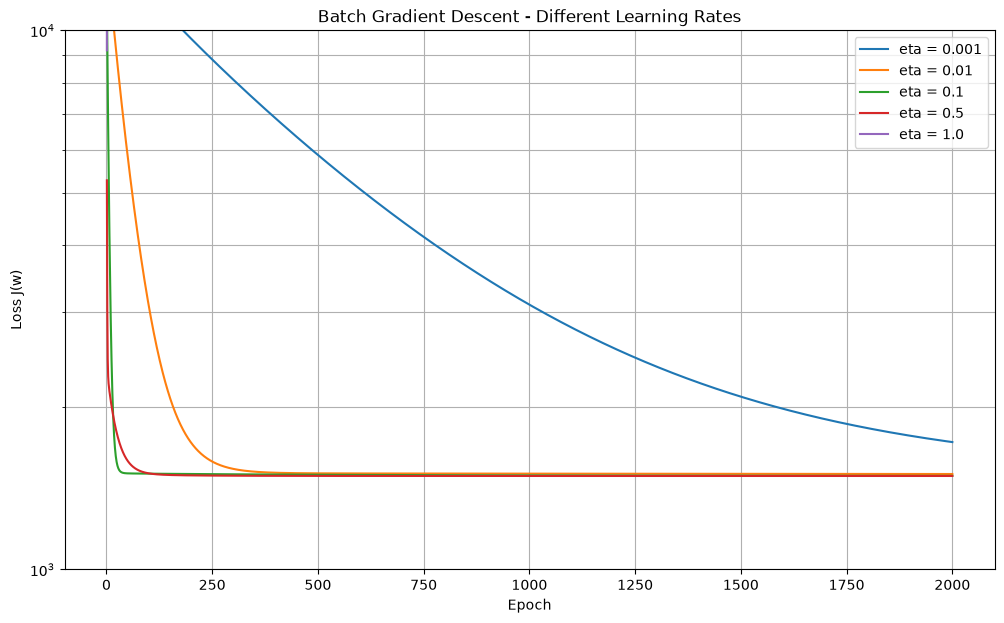

In [588]:
import matplotlib.pyplot as plt
import numpy as np

plt.close('all')

fig, ax = plt.subplots(figsize=(12, 7))

for eta, result in gd_results.items():

    losses = result["losses"]

    epochs = np.arange(1, len(losses) + 1)

    valid = np.isfinite(losses) & (losses > 0)

    print(f"Eta {eta}: plotting {np.sum(valid)} points")

    ax.plot(
        epochs[valid],
        losses[valid],
        label=f"eta = {eta}"
    )

ax.set_yscale('log')
ax.set_ylim(1000, 10000)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss J(w)")
ax.set_title("Batch Gradient Descent - Different Learning Rates")

ax.legend()
ax.grid(True, which='both')

plt.show()

With a small learning rate of 0.001, the loss decreases very slowly and does not reach the minimum within 2000 epochs. Increasing the learning rate to 0.01, 0.1, and 0.5 makes the loss decrease much faster. However, a learning rate of 1.0 causes divergence, as the updates become too large and the loss increases.

In [589]:

results = []

for eta, result in gd_results.items():

    losses = result["losses"]
    distances = result["distances"]

    diverged = len(losses) < 2000

    if len(losses) == 0:
        final_loss = np.nan
        final_distance = np.nan
        first_epoch = "Diverged"

    else:
        final_loss = losses[-1]
        final_distance = distances[-1]

        reached = np.where(distances < 1e-3)[0]

        if len(reached) > 0:
            first_epoch = reached[0] + 1
        elif diverged:
            first_epoch = "Diverged"
        else:
            first_epoch = "Not reached"

    results.append({
        "Learning Rate": eta,
        "Final Loss": final_loss,
        "Final Relative Distance": final_distance,
        "First Epoch < 1e-3": first_epoch
    })

results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))


 Learning Rate    Final Loss  Final Relative Distance First Epoch < 1e-3
         0.001  1.723403e+03             4.051131e-01        Not reached
         0.010  1.503687e+03             3.345214e-01        Not reached
         0.100  1.491893e+03             8.179229e-02        Not reached
         0.500  1.491146e+03             1.546262e-04               1524
         1.000 1.035714e+305            1.354569e+150           Diverged


 increasing the learning rate generally improves convergence speed. A learning rate of 0.001 makes very slow progress, while 0.01 and 0.1 achieve lower final losses but do not reach the required relative distance of (10^-3) within 2000 epochs. A learning rate of 0.5 performs best among the tested values, reaching the required threshold at epoch 1524 with a final relative distance of approximately (1.55 \times 10^-4). However, a learning rate of 1.0 causes divergence.learning rate must be chosen carefully to balance convergence speed and stability.

In [590]:
N = len(y_train)
H = (X_train_bias.T @ X_train_bias) / N

eigenvalues = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalues)
eta_threshold = 2 / lambda_max

print("Largest eigenvalue:", lambda_max)
print("Convergence threshold:", eta_threshold)

# Learning rates around the threshold
eta_below = 0.95 * eta_threshold
eta_above = 1.05 * eta_threshold

# Run gradient descent
w_below, loss_below, dist_below = batch_gradient_descent(
    X_train_bias, y_train, eta_below, 2000,w_star
)

w_above, loss_above, dist_above = batch_gradient_descent(
    X_train_bias, y_train, eta_above, 2000,w_star
)

print("\nLearning rate below threshold:", eta_below)
print("Final distance:", dist_below[-1])

print("\nLearning rate above threshold:", eta_above)
print("Final distance:", dist_above[-1])

Largest eigenvalue: 3.954755032050376
Convergence threshold: 0.5057203249737274

Learning rate below threshold: 0.48043430872504106
Final distance: 0.000210230753136441

Learning rate above threshold: 0.5310063412224139
Final distance: 7.581863342433239e+81


////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////

In [591]:
# raw data
X_train_raw = add_bias(X_train)
X_val_raw = add_bias(X_val)
X_test_raw = add_bias(X_test)

In [592]:
# Standardized features
H_std = (X_train_bias.T @ X_train_bias) / N
eigenvalues_std = np.linalg.eigvalsh(H_std)
cond_std = np.linalg.cond(X_train_bias.T @ X_train_bias)
eta_max_std = 2 / np.max(eigenvalues_std)


# Raw features
H_raw = (X_train_raw.T @ X_train_raw) / N
eigenvalues_raw = np.linalg.eigvalsh(H_raw)
cond_raw = np.linalg.cond(X_train_raw.T @ X_train_raw)
eta_max_raw = 2 / np.max(eigenvalues_raw)


print("Standardized features:")
print("Condition number:", cond_std)
print("Maximum learning rate:", eta_max_std)

print("\nRaw features:")
print("Condition number:", cond_raw)
print("Maximum learning rate:", eta_max_raw)

Standardized features:
Condition number: 505.70612269609745
Maximum learning rate: 0.5057203249737274

Raw features:
Condition number: 55778473.21759959
Maximum learning rate: 2.7427928748390996e-05


In [593]:

def batch_gd_raw(X, y, eta, epochs, w_star):
    w = np.zeros(X.shape[1])

    losses = []
    distances = []

    for epoch in range(epochs):

        gradient = linear_gradient(X, y, w)

        if not np.all(np.isfinite(gradient)):
            break

        w = w - eta * gradient

        current_loss = linear_loss(X, y, w)

        distance = (
            np.linalg.norm(w - w_star) /
            np.linalg.norm(w_star)
        )

        if not np.isfinite(current_loss) or not np.isfinite(distance):
            break

        losses.append(current_loss)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [594]:

w_star_raw = normal_equation(X_train_raw, y_train)

raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = {}

for eta in raw_learning_rates:

    w, losses, distances = batch_gd_raw(
        X_train_raw,
        y_train,
        eta,
        2000,
        w_star_raw
    )

    raw_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }


/home/asmaa/myenv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


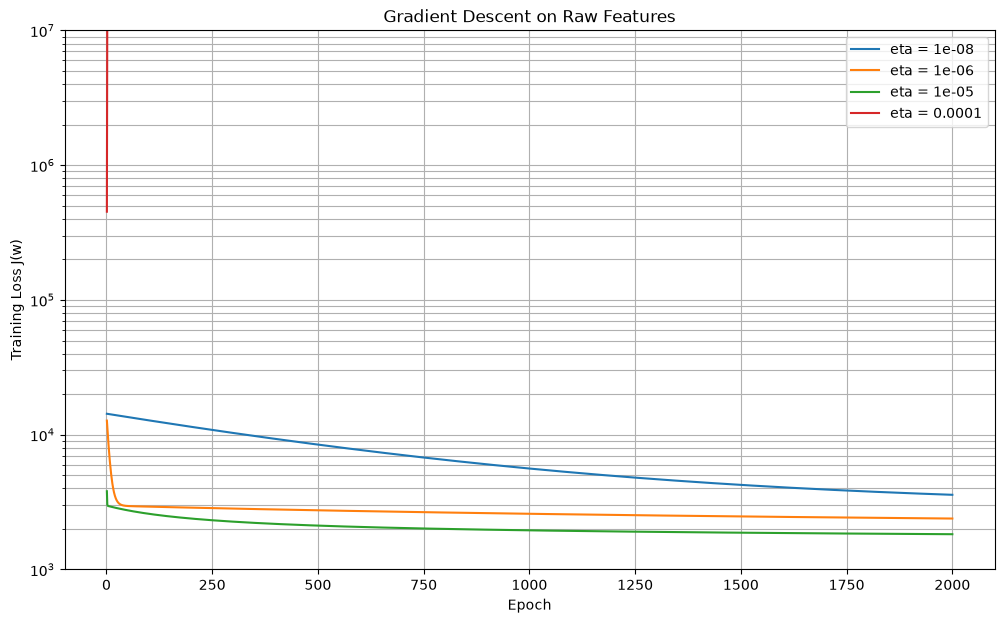

In [595]:
plt.close('all')
fig, ax = plt.subplots(figsize=(12, 7))
for eta, result in raw_results.items():

    losses = result["losses"]
    epochs = np.arange(1, len(losses) + 1)
    valid = np.isfinite(losses) & (losses > 0)
    ax.plot(
        epochs[valid],
        losses[valid],
        label=f"eta = {eta}"
    )

# Set a viewing range that shows the initial divergence
ax.set_ylim(1000, 1e7)

ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss J(w)")
ax.set_title("Gradient Descent on Raw Features")

ax.legend()
ax.grid(True, which="both")

plt.show()

The plot shows that Gradient Descent converges much more slowly when using raw features compared to standardized features.This happens because raw features have very different scales, making the optimization problem poorly conditioned and requiring much smaller learning rates.

In [596]:

results = []

for eta, result in raw_results.items():

    losses = result["losses"]
    distances = result["distances"]

    diverged = len(losses) < 2000

    if len(losses) == 0:
        final_loss = np.nan
        final_distance = np.nan
        first_epoch = "Diverged"

    else:
        final_loss = losses[-1]
        final_distance = distances[-1]

        reached = np.where(distances < 1e-3)[0]

        if len(reached) > 0:
            first_epoch = reached[0] + 1
        elif diverged:
            first_epoch = "Diverged"
        else:
            first_epoch = "Not reached"

    results.append({
        "Learning Rate": eta,
        "Final Loss": final_loss,
        "Final Relative Distance": final_distance,
        "First Epoch < 1e-3": first_epoch
    })

print(pd.DataFrame(results).to_string(index=False))

 Learning Rate    Final Loss  Final Relative Distance First Epoch < 1e-3
  1.000000e-08  3.583532e+03             9.999986e-01        Not reached
  1.000000e-06  2.388753e+03             9.999676e-01        Not reached
  1.000000e-05  1.827535e+03             9.998464e-01        Not reached
  1.000000e-04 2.484752e+304            2.172173e+147           Diverged


The results show that Gradient Descent makes very slow progress when using raw features. Increasing the learning rate from 10^-8 to 10^-5 reduces the final loss, and 10^-5 achieves the lowest loss among the stable learning rates.

In [597]:
J_star_raw = linear_loss(
    X_train_raw,
    y_train,
    w_star_raw
)

print("Optimal raw training loss:", J_star_raw)

Optimal raw training loss: 1491.1459048007398


The condition number increases from approximately 505.71 for standardized features to 55,778,473.22 for raw features, indicating that the raw feature matrix is much more poorly conditioned. This also reduces the maximum usable learning rate from approximately 0.50572 to 0.00002743, making much smaller learning rates necessary for raw features. As a result, gradient descent makes much slower progress on raw features and requires many more epochs to approach the optimal solution. After 2000 epochs, none of the tested raw learning rates gets close to the optimal loss, while the learning rate 10^-4, which exceeds the convergence threshold, diverges.

//////////////////////////////////////////////////////
//////////////////////////////////////////////////////
//////////////////////////////////////////////////////
//////////////////////////////////////////////////////

In [598]:
def mini_batch_gd(X, y, eta, epochs, batch_size):
    N, d = X.shape
    w = np.zeros(d)

    losses = []
    updates = []

    rng = np.random.default_rng(42)

    updates_per_epoch = int(np.ceil(N / batch_size))
    total_updates = 0

    for epoch in range(epochs):

        # Shuffle training indices every epoch
        indices = rng.permutation(N)

        # Divide into batches
        for start in range(0, N, batch_size):

            batch_indices = indices[start:start + batch_size]

            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            # Calculate batch gradient
            gradient = linear_gradient(
                X_batch,
                y_batch,
                w
            )

            # Update weights
            w = w - eta * gradient
            total_updates += 1

        # Calculate loss on the complete training set
        losses.append(linear_loss(X, y, w))
        updates.append(total_updates)

    return w, np.array(losses), np.array(updates)

In [599]:
batch_sizes = [1, 16, 64, N]
mini_results = {}
for B in batch_sizes:
    

    w, losses, updates = mini_batch_gd(
        X_train_bias,
        y_train,
        eta=0.01,
        epochs=100,
        batch_size=B
    )

    mini_results[B] = {
        "weights": w,
        "losses": losses,
        "updates": updates
    }

In [600]:
for B in batch_sizes:
    print(
        f"B = {B}: "
        f"Total parameter updates = {mini_results[B]['updates'][-1]}, "     
        f"{len(mini_results[B]['losses'])} losses, "
        f"{len(mini_results[B]['updates'])} updates"
    )

B = 1: Total parameter updates = 26400, 100 losses, 100 updates
B = 16: Total parameter updates = 1700, 100 losses, 100 updates
B = 64: Total parameter updates = 500, 100 losses, 100 updates
B = 264: Total parameter updates = 100, 100 losses, 100 updates


The number of parameter updates depends on the batch size. With B=1, the algorithm performs 264 updates per epoch, resulting in 26,400 updates over 100 epochs. As the batch size increases, the number of updates decreases: 1,700 for B=16, 500 for B=64, and 100 for B=264. The full-batch case performs only one update per epoch because it uses all 264 training samples in each update. All configurations have 100 recorded losses and 100 recorded update counts because the loss and cumulative number of updates are recorded once at the end of each epoch.

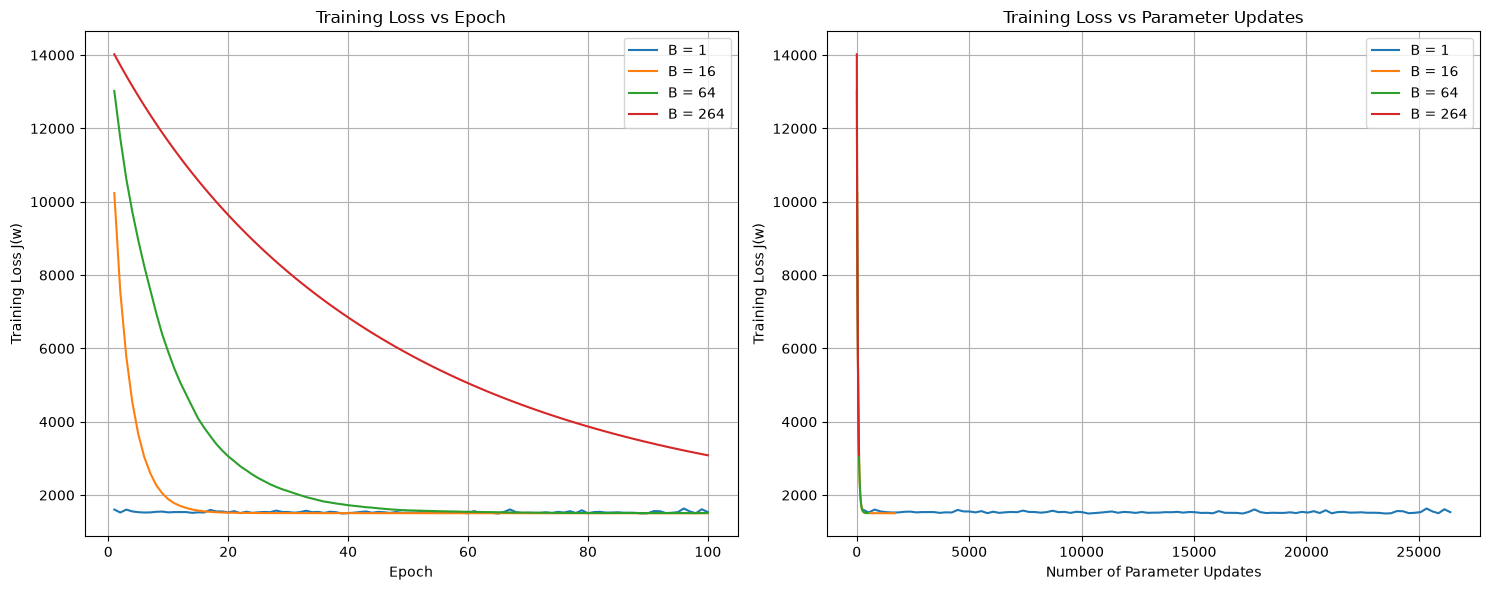

In [601]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for B in batch_sizes:

    result = mini_results[B]
    # Left panel: Loss vs Epoch
    epochs = np.arange(1, len(result["losses"]) + 1)

    axes[0].plot(
        epochs,
        result["losses"],
        label=f"B = {B}"
    )

    # Right panel: Loss vs Parameter Updates
    axes[1].plot(
        result["updates"],
        result["losses"],
        label=f"B = {B}"
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss J(w)")
axes[0].set_title("Training Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss J(w)")
axes[1].set_title("Training Loss vs Parameter Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Best per epoch:B=1 (SGD), because it performs the largest number of parameter updates per epoch and reaches a low training loss quickly.

Best per parameter update: B=64, because it achieves a good reduction in loss with relatively few updates while maintaining stable progress.

For B=1, each update uses only one training example to calculate the gradient.

That gradient may not represent the direction that reduces the loss across the entire dataset. Different samples can produce different gradient directions, so the weights keep changing in somewhat different directions.

For larger batches, gradients are averaged across more samples, making the updates more stable.

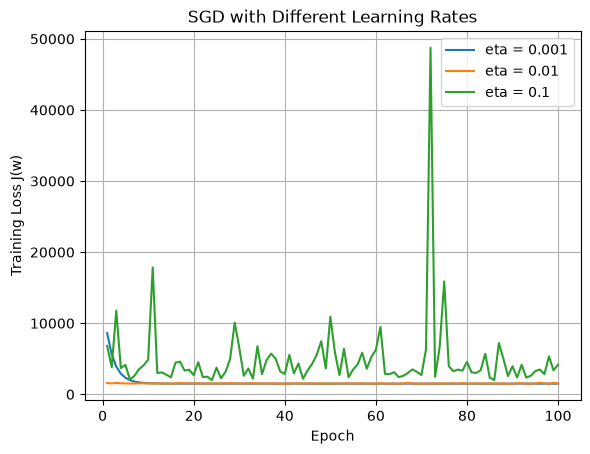

In [602]:
sgd_rates = [0.001, 0.01, 0.1]
sgd_results = {}
for eta in sgd_rates:

    w, losses, updates = mini_batch_gd(
        X_train_bias,
        y_train,
        eta=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = losses

# Plot
for eta in sgd_rates:

    plt.plot(
        range(1, 101),
        sgd_results[eta],
        label=f"eta = {eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss J(w)")
plt.title("SGD with Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

When using B=1, increasing the learning rate from 0.001 to 0.01 makes the loss decrease faster but also increases its fluctuations. At eta=0.1, the loss becomes highly unstable, with large spikes because the updates are too large. Therefore, increasing the learning rate generally increases the noise and can make SGD unstable.

/////////////////////////////////////////////////////////
/////////////////////////////////////////////////////////
/////////////////////////////////////////////////////////

Jλ(w) = (1 / 2N) ||X̃w - y||² + (λ / 2) ||w₁:||²
Jλ(w) = (1 / 2N)(X̃w - y)ᵀ(X̃w - y) + (λ / 2)wᵀI₀w

Differentiate:
∇Jλ(w) = (1 / N)X̃ᵀ(X̃w - y) + λI₀w
(1 / N)X̃ᵀ(X̃w - y) + λI₀w = 0
(1 / N)X̃ᵀX̃w - (1 / N)X̃ᵀy + λI₀w = 0
(1 / N)X̃ᵀX̃w + λI₀w = (1 / N)X̃ᵀy
(X̃ᵀX̃ / N + λI₀)w = X̃ᵀy / N
w* = (X̃ᵀX̃ / N + λI₀)⁻¹ (X̃ᵀy / N)

In [603]:
X_example = np.array([
    [1, 1],
    [1, 2],
    [1, 3]
], dtype=float)

y_example = np.array([2, 3, 5], dtype=float)
lambda_example = 1
N_example = len(y_example)
I0_example = np.eye(X_example.shape[1])
I0_example[0, 0] = 0

A_example = (
    X_example.T @ X_example / N_example
    + lambda_example * I0_example
)

b_example = X_example.T @ y_example / N_example
w_example = np.linalg.solve(A_example, b_example)
print("Ridge weights:", w_example)

Ridge weights: [2.13333333 0.6       ]


In [604]:
def ridge_regression(X, y, lam):
    N, d = X.shape
    # Identity matrix
    I0 = np.eye(d)
    # Do not regularize the bias
    I0[0, 0] = 0

    A = (X.T @ X) / N + lam * I0
    b = (X.T @ y) / N
    w = np.linalg.solve(A, b)

    return w

In [605]:
lambda_values = np.concatenate((
    [0],
    np.logspace(-3, 1, 9)
))

ridge_original_results = {}

for lam in lambda_values:

    w = ridge_regression(
        X_train_bias,
        y_train,
        lam
    )

    train_pred = X_train_bias @ w
    val_pred = X_val_bias @ w
    test_pred = X_test_bias @ w

    ridge_original_results[lam] = {
        "weights": w,
        "train_rmse": rmse(y_train, train_pred),
        "val_rmse": rmse(y_val, val_pred),
        "test_rmse": rmse(y_test, test_pred)
    }

In [606]:
def degree2_expansion(X, feature_names):
    features = [X]
    names = list(feature_names)
    sex_index = list(feature_names).index("sex")

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):

            # Drop sex squared
            if i == sex_index and j == sex_index:
                continue

            # Add product feature
            features.append(
                (X[:, i] * X[:, j]).reshape(-1, 1)
            )

            names.append(
                f"{feature_names[i]}*{feature_names[j]}"
            )

    return np.column_stack(features), names


# Create degree-2 features
X_train_exp, expanded_names = degree2_expansion(
    X_train,
    diabetes.feature_names
)

X_val_exp, _ = degree2_expansion(
    X_val,
    diabetes.feature_names
)

X_test_exp, _ = degree2_expansion(
    X_test,
    diabetes.feature_names
)

print("Expanded feature count:", X_train_exp.shape[1])


Expanded feature count: 64


In [607]:
expanded_scaler = Standardizer()
expanded_scaler.fit(X_train_exp)

X_train_exp_std = expanded_scaler.transform(X_train_exp)
X_val_exp_std = expanded_scaler.transform(X_val_exp)
X_test_exp_std = expanded_scaler.transform(X_test_exp)

# Add bias
X_train_exp_bias = add_bias(X_train_exp_std)
X_val_exp_bias = add_bias(X_val_exp_std)
X_test_exp_bias = add_bias(X_test_exp_std)

print("Training expanded shape:", X_train_exp_bias.shape)
print("Validation expanded shape:", X_val_exp_bias.shape)
print("Testing expanded shape:", X_test_exp_bias.shape)

# Condition number
cond_expanded = np.linalg.cond(
    X_train_exp_bias.T @ X_train_exp_bias
)

print("Expanded condition number:", cond_expanded)

Training expanded shape: (264, 65)
Validation expanded shape: (89, 65)
Testing expanded shape: (89, 65)
Expanded condition number: 1289356234.6280315


In [608]:
ridge_expanded_results = {}
for lam in lambda_values:

    w = ridge_regression(
        X_train_exp_bias,
        y_train,
        lam
    )

    train_pred = X_train_exp_bias @ w
    val_pred = X_val_exp_bias @ w
    test_pred = X_test_exp_bias @ w

    ridge_expanded_results[lam] = {
        "weights": w,
        "train_rmse": rmse(y_train, train_pred),
        "val_rmse": rmse(y_val, val_pred),
        "test_rmse": rmse(y_test, test_pred)
    }

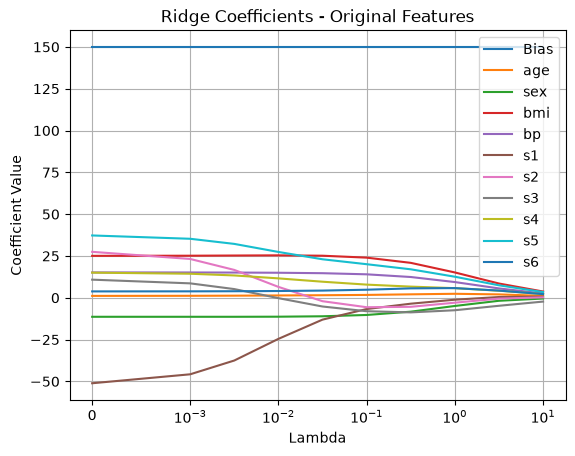

In [609]:
for i, name in enumerate(feature_names):
    coefficients = [
        ridge_original_results[lam]["weights"][i]
        for lam in lambda_values
    ]

    plt.plot(
        lambda_values,
        coefficients,
        label=name
    )

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients - Original Features")
plt.legend()
plt.grid(True)

plt.show()

As the regularization parameter lambda increases, the feature coefficients generally shrink toward zero. This shows how Ridge Regression reduces the influence of features to help prevent overfitting. The coefficient of s1 starts with a large negative value, while s5 has a large positive value; both become smaller as regularization increases. The bias remains unchanged because Ridge Regression does not penalize the intercept. At high values of lambda, most feature coefficients become close to zero.

/tmp/ipykernel_87264/2400263234.py:25: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


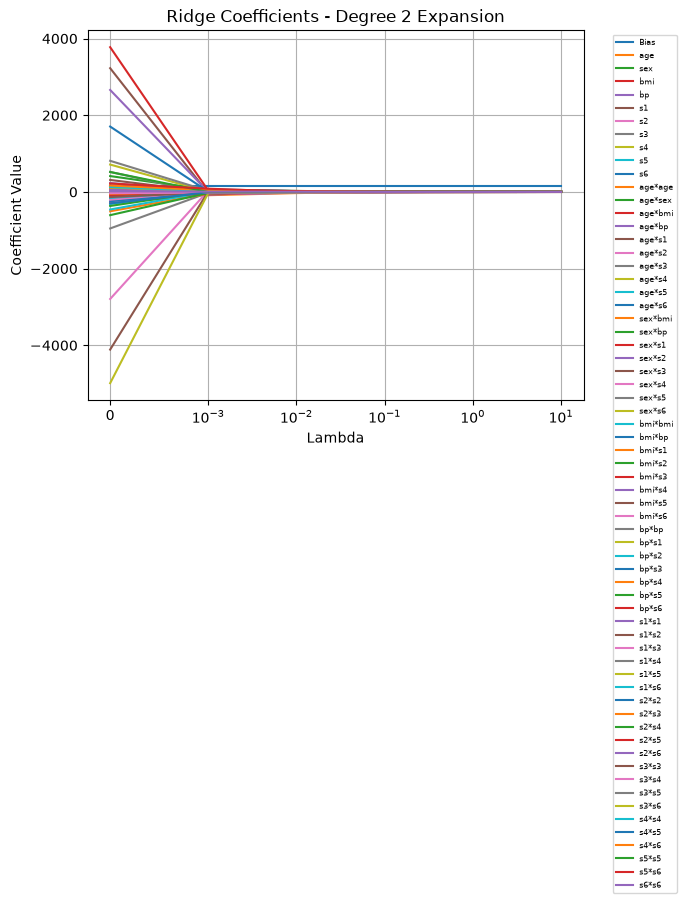

In [610]:

expanded_feature_names = ["Bias"] + expanded_names
for i, name in enumerate(expanded_feature_names):

    coefficients = [
        ridge_expanded_results[lam]["weights"][i]
        for lam in lambda_values
    ]

    plt.plot(
        lambda_values,
        coefficients,
        label=name
    )

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients - Degree 2 Expansion")
plt.grid(True)
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=6
)
plt.tight_layout()
plt.show()


The degree-2 expanded model has much larger coefficient values when lambda=0, with some coefficients reaching approximately 5000 in magnitude. As lambda increases, the coefficients shrink rapidly toward zero. This shows that the expanded model is more sensitive to regularization because it contains many polynomial features. Ridge Regression controls these large coefficients, helping reduce overfitting and improve model stability. The bias remains unpenalized.

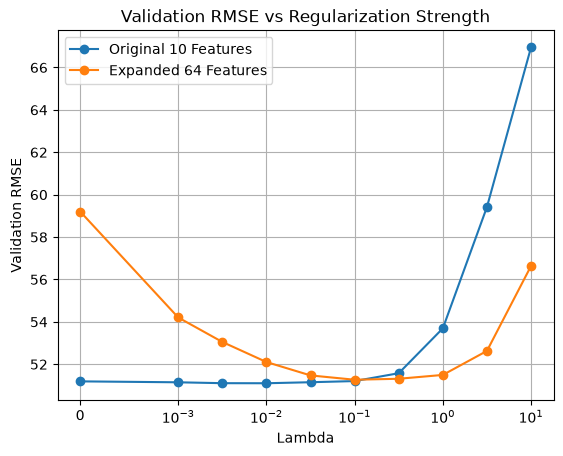

In [611]:
original_val_rmse = [
    ridge_original_results[lam]["val_rmse"]
    for lam in lambda_values
]

expanded_val_rmse = [
    ridge_expanded_results[lam]["val_rmse"]
    for lam in lambda_values
]

plt.plot(
    lambda_values,
    original_val_rmse,
    marker="o",
    label="Original 10 Features"
)

plt.plot(
    lambda_values,
    expanded_val_rmse,
    marker="o",
    label="Expanded 64 Features"
)

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Regularization Strength")
plt.legend()
plt.grid(True)

plt.show()

The original 10-feature model achieves a lower validation RMSE than the expanded model when no regularization is used, because the expanded model has more features and is more prone to overfitting. As lambda increases, the expanded model's validation RMSE decreases significantly, showing that regularization helps control overfitting. Both models achieve their lowest validation errors at relatively small regularization values. However, when lambda becomes too large, the validation RMSE increases because the coefficients are excessively reduced, leading to underfitting. This shows the importance of selecting an appropriate regularization strength using validation data.

In [612]:
best_lambda_original = min(
    lambda_values,
    key=lambda lam: ridge_original_results[lam]["val_rmse"]
)

best_lambda_expanded = min(
    lambda_values,
    key=lambda lam: ridge_expanded_results[lam]["val_rmse"]
)

print("Best lambda - Original:",
      best_lambda_original)

print("Best lambda - Expanded:",
      best_lambda_expanded)

print("\nOriginal model:")
print("Lambda = 0 test RMSE:",
      ridge_original_results[0]["test_rmse"])

print("Best lambda test RMSE:",
      ridge_original_results[best_lambda_original]["test_rmse"])

print("\nExpanded model:")
print("Lambda = 0 test RMSE:",
      ridge_expanded_results[0]["test_rmse"])

print("Best lambda test RMSE:",
      ridge_expanded_results[best_lambda_expanded]["test_rmse"])


Best lambda - Original: 0.01
Best lambda - Expanded: 0.1

Original model:
Lambda = 0 test RMSE: 54.15641293326043
Best lambda test RMSE: 53.9584521494208

Expanded model:
Lambda = 0 test RMSE: 62.133373392121314
Best lambda test RMSE: 53.615580116744916


In [613]:
def ridge_gradient(X, y, w, lam):
    N = len(y)
    I0 = np.eye(X.shape[1])
    I0[0, 0] = 0

    gradient = (X.T @ (X @ w - y)) / N

    gradient += lam * (I0 @ w)

    return gradient


# Batch GD for Ridge
def ridge_gd(X, y, lam, eta, epochs):
    w = np.zeros(X.shape[1])
    for epoch in range(epochs):
        gradient = ridge_gradient(X, y, w, lam)
        w = w - eta * gradient

    return w

lambda_ridge = 0.1

w_ridge_closed = ridge_regression(
    X_train_bias,
    y_train,
    lambda_ridge
)

w_ridge_gd = ridge_gd(
    X_train_bias,
    y_train,
    lam=0.1,
    eta=0.4,
    epochs=3000
)

relative_distance = (
    np.linalg.norm(w_ridge_gd - w_ridge_closed)
    / np.linalg.norm(w_ridge_closed)
)

print("Relative distance:", relative_distance)
assert relative_distance < 1e-6
print("Ridge GD verification passed!")

Relative distance: 8.351521031972526e-16
Ridge GD verification passed!


In [614]:
from sklearn.linear_model import Ridge

ridge_sklearn = Ridge(
    alpha=0.1 * N
)

ridge_sklearn.fit(X_train_std, y_train)

w_ridge_sklearn = np.concatenate((
    [ridge_sklearn.intercept_],
    ridge_sklearn.coef_
))

print("Our Ridge weights:")
print(w_ridge_closed)

print("\nSklearn Ridge weights:")
print(w_ridge_sklearn)

print("\nMaximum difference:",
      np.max(np.abs(w_ridge_closed - w_ridge_sklearn)))

assert np.allclose(
    w_ridge_closed,
    w_ridge_sklearn,
    atol=1e-6
)

print("\nRidge sklearn verification passed!")

Our Ridge weights:
[149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]

Sklearn Ridge weights:
[149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]

Maximum difference: 1.5720758028692217e-13

Ridge sklearn verification passed!


Ridge regularization provides only a small improvement with the original 10 features because the number of features is relatively small compared with the number of training samples, so overfitting is limited. However, the degree-2 expansion increases the number of features to 64 while the training set still contains only 264 samples, making the model more likely to overfit. Ridge reduces the effect of this overfitting by penalizing large feature coefficients, improving generalization on the validation and test sets. The bias must not be penalized because it represents the intercept of the model, and penalizing it would unnecessarily restrict the model's ability to adjust its predictions' baseline.

////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////

In [615]:
import time
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    SGDRegressor
)

In [616]:
comparison_results = []
def add_result(name, w, fit_time):

    predictions = X_test_bias @ w
    test_error = rmse(y_test, predictions)

    relative_distance = (
        np.linalg.norm(w - w_star)
        / np.linalg.norm(w_star)
    )

    comparison_results.append({
        "Method": name,
        "Test RMSE": test_error,
        "Relative Distance": relative_distance,
        "Fit Time (seconds)": fit_time
    })

In [617]:
start = time.perf_counter()
w_normal = normal_equation(
    X_train_bias,
    y_train
)

normal_time = time.perf_counter() - start

add_result(
    "Normal Equation",
    w_normal,
    normal_time
)

In [618]:
start = time.perf_counter()
w_batch, losses_batch, distances_batch = batch_gradient_descent(
    X_train_bias,
    y_train,
    eta=0.5,
    epochs=2000,
    w_star=w_star
)

batch_time = time.perf_counter() - start

add_result(
    "Batch GD",
    w_batch,
    batch_time
)

In [619]:
start = time.perf_counter()

w_mini, losses_mini, updates_mini = mini_batch_gd(
    X_train_bias,
    y_train,
    eta=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start

add_result(
    "Mini-batch GD",
    w_mini,
    mini_time
)


In [620]:
start = time.perf_counter()
w_ridge = ridge_regression(
    X_train_bias,
    y_train,
    lam=0.1
)

ridge_time = time.perf_counter() - start

add_result(
    "Ridge",
    w_ridge,
    ridge_time
)

In [621]:
linear_model = LinearRegression()
start = time.perf_counter()
linear_model.fit(X_train_std, y_train)
linear_time = time.perf_counter() - start
w_linear_sklearn = np.concatenate((
    [linear_model.intercept_],
    linear_model.coef_
))

add_result(
    "Sklearn LinearRegression",
    w_linear_sklearn,
    linear_time
)

In [622]:
ridge_model = Ridge(alpha=0.1 * N)
start = time.perf_counter()
ridge_model.fit(X_train_std, y_train)
ridge_sklearn_time = time.perf_counter() - start

w_ridge_sklearn = np.concatenate((
    [ridge_model.intercept_],
    ridge_model.coef_
))

add_result(
    "Sklearn Ridge",
    w_ridge_sklearn,
    ridge_sklearn_time
)

In [623]:
sgd_learning_rates = [0.001, 0.01, 0.1]
sgd_models = {}

for eta in sgd_learning_rates:

    model = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_train_std, y_train)
    fit_time = time.perf_counter() - start

    w_sgd = np.concatenate((
        [model.intercept_[0]],
        model.coef_
    ))

    add_result(
        f"SGDRegressor eta={eta}",
        w_sgd,
        fit_time
    )

    sgd_models[eta] = model

In [624]:
comparison_table = pd.DataFrame(comparison_results)
print(comparison_table.to_string(index=False))

                  Method  Test RMSE  Relative Distance  Fit Time (seconds)
         Normal Equation  54.156413       0.000000e+00            0.000638
                Batch GD  54.156254       1.546262e-04            0.080576
           Mini-batch GD  53.895449       3.421471e-01            0.020809
                   Ridge  53.708925       3.636136e-01            0.000276
Sklearn LinearRegression  54.156413       8.801221e-15            0.003873
           Sklearn Ridge  53.708925       3.636136e-01            0.004573
  SGDRegressor eta=0.001  54.088486       4.976050e-02            0.023126
   SGDRegressor eta=0.01  54.898061       5.031993e-02            0.013154
    SGDRegressor eta=0.1  71.449348       3.949685e-01            0.012925


Batch Gradient Descent achieves a relative distance of (1.55* 10^-4), showing that it closely approximates the Normal Equation solution. Ridge achieves the lowest test RMSE (53.71), followed by Mini-batch GD (53.90). The Ridge model also has a lower test RMSE than the unregularized Normal Equation model. Among the tested SGD learning rates, 0.001 gives the lowest test RMSE, while 0.1 gives the worst result (71.45), indicating that a high learning rate can negatively affect convergence.

In [625]:
# Normal Equation vs LinearRegression
print(
    "Normal Equation vs LinearRegression:",
    np.max(np.abs(w_normal - w_linear_sklearn))
)

# Ridge vs sklearn Ridge
print(
    "Ridge vs sklearn Ridge:",
    np.max(np.abs(w_ridge - w_ridge_sklearn))
)

assert np.allclose(
    w_normal,
    w_linear_sklearn,
    atol=1e-10
)

assert np.allclose(
    w_ridge,
    w_ridge_sklearn,
    atol=1e-10
)

print("\nExact solver verification passed!")

Normal Equation vs LinearRegression: 1.0089706847793423e-12
Ridge vs sklearn Ridge: 1.5720758028692217e-13

Exact solver verification passed!


The Normal Equation and sklearn LinearRegression produce almost identical results because both calculate the same least-squares solution. Similarly, our Ridge implementation and sklearn Ridge agree because they use the same regularization objective when alpha = λ × N_train. However, gradient descent and SGDRegressor may produce different results because they use iterative optimization, and their accuracy depends on the learning rate and number of updates.

In [626]:
X_tr, X_va, X_te, y_tr, y_va, y_te = breast_split

scaler = Standardizer()
scaler.fit(X_tr)
X_tr_std=scaler.transform(X_tr)
X_va_std=scaler.transform(X_va)
X_te_std=scaler.transform(X_te)
X_tr_bias=add_bias(X_tr_std)
X_va_bias=add_bias(X_va_std)
X_te_bias=add_bias(X_te_std)
N = len(y_tr)
print("Training shape without bias:", X_tr.shape)
print("Validation shape without bias:", X_va.shape)
print("Testing shape without bias:", X_te.shape)
print("Training shape with bias:", X_tr_bias.shape)
print("Validation shape with bias:", X_va_bias.shape)
print("Testing shape with bias:", X_te_bias.shape)
# print("Number of training samples:", N)
# print("Number of validation samples:", len(y_va))
# print("Number of testing samples:", len(y_te))
print("Labels:", np.unique(y_tr))
# print("Labels:", np.unique(y_va))
# print("Labels:", np.unique(y_te))
print(breast_cancer.feature_names)


Training shape without bias: (341, 30)
Validation shape without bias: (114, 30)
Testing shape without bias: (114, 30)
Training shape with bias: (341, 31)
Validation shape with bias: (114, 31)
Testing shape with bias: (114, 31)
Labels: [0 1]
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [627]:
def naive_sigmoid(z):
    return 1/(1+np.exp(-z))


def naive_loss(z,y):
    p=naive_sigmoid(z)
    return -(y*np.log(p)+(1-y)*np.log(1-p))

-"Derive ∇J = (1/N) X̃T(p − y) + λ[0, w1:] using σ′(z) = σ(z)(1 − σ(z))":

li=−[yi*log(pi)+(1−yi)*log(1−pi)]
pi=σ(zi)
zi=wT*X̃i

Differentiate the loss with respect to its probability
∂l/∂pi= -yi/pi +(1-yi)/(1-pi)
= (-yi(1-pi)+pi(1-yi))/(pi*(1-pi))
=  (-yi+yipi+pi-piyi)/(pi*(1-pi))
= (-yi+pi)/(pi*(1-pi))

Differentiate the pi with respect to its zi
σ′(zi) = σ(zi)(1 − σ(zi))= pi(1-pi)

Differentiate the loss with respect to its zi
∂l/∂zi= ∂l/∂pi*∂pi/∂zi
= ((-yi+pi)/(pi*(1-pi)))*pi(1-pi)
=(-yi+pi)

Differentiate the zi with respect to its w
∂zi/∂w=X̃i

Differentiate the loss with respect to its w
∂l/∂w=∂l/∂zi*∂zi/∂w=(-yi+pi)*X̃i
=(pi-yi)*X̃i

∇J =(1/N)X̃T(p − y)+λ[0, w1:]


-"show that the per-sample loss equals log(1+e^z) − y·z."

l=−[y*log(p)+(1−y)*log(1−p)]
p=σ(z)=1/1+e^-z

so
log(p)=log(1/1+e^-z)
=log((1+e^-z)^-1)
=-log(1+e^-z)

1-p=e^-z/1+e^-z
log(1-p)=log(e^-z/1+e^-z)
=log(e^-z)-log(1+e^-z)
=-zlog(e)-log(1+e^-z)
=-z-log(1+e^-z)

Substitute into the loss:
l=ylog(1+e^-z)+(1-y)z+(1-y)log(1+e^-z)
=log(1+e^-z)+(1-y)z         (eqn 1)

log(1+e^-z)= log(e^-z(1+e^z))
=-zlog(e)+log(1+e^z)
=-z+log(1+e^z)

back to (eqn 1)
-z+log(1+e^z)+(1-y)z 
log(1+e^z)-yz

In [628]:
def sigmoid(z):
    z=np.asarray(z,float) #convert z into a NumPy array of floats to perform operations such as: exp
    p=np.empty(z.shape)
    positive=z>=0
    negative =z<0
    p[positive]=1/(1+np.exp(-z[positive]))
    p[negative]=np.exp(z[negative])/(np.exp(z[negative])+1)
    return p

def stable_loss(z,y):
    return np.logaddexp(0,z)-y*z

In [629]:
for z in [800,-800]:
    for y in [0, 1]:
        print("z =",z,"y =",y)
        print("Naive sigmoid:",naive_sigmoid(z))
        print("Stable sigmoid:",sigmoid(z))
        print("Naive loss:",naive_loss(z,y))
        print("Stable loss:",stable_loss(z,y))
        print("\n")

z = 800 y = 0
Naive sigmoid: 1.0
Stable sigmoid: 1.0
Naive loss: inf
Stable loss: 800.0


z = 800 y = 1
Naive sigmoid: 1.0
Stable sigmoid: 1.0
Naive loss: nan
Stable loss: 0.0


z = -800 y = 0
Naive sigmoid: 0.0
Stable sigmoid: 0.0
Naive loss: nan
Stable loss: 0.0


z = -800 y = 1
Naive sigmoid: 0.0
Stable sigmoid: 0.0
Naive loss: inf
Stable loss: 800.0




/tmp/ipykernel_87264/2679163861.py:7: RuntimeWarning: divide by zero encountered in log
  return -(y*np.log(p)+(1-y)*np.log(1-p))
/tmp/ipykernel_87264/2679163861.py:7: RuntimeWarning: invalid value encountered in scalar multiply
  return -(y*np.log(p)+(1-y)*np.log(1-p))
/tmp/ipykernel_87264/2679163861.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-z))


The stable sigmoid and stable loss function avoid overflow and invalid values for very large positive and negative inputs. Unlike the naive implementation, the stable loss produces finite results for z=800 and z=-800.

In [630]:
def compute_loss(X,y,w,lam):
    z=X@w
    dataloss =np.mean(stable_loss(z, y))
    regularization =(lam/2)*np.sum(w[1:]**2)
    return dataloss+regularization


In [631]:
def compute_gradient(X, y, w, lam):
    N=len(y)  #We divide by N later because we calculate the average gradient.
    z=X@w
    p=sigmoid(z)
    gradient=(X.T@(p-y))/N
    gradient[1:]+=lam*w[1:]
    return gradient

In [632]:
def numerical_gradient(X,y,w,lam,eps=1e-5):
    grad = np.zeros(w.shape)
    for i in range(len(w)):
        wplus=w.copy()
        wminus=w.copy()
        wplus[i]+=eps
        wminus[i]-=eps
        lossplus=compute_loss(X,y,wplus,lam)
        lossminus=compute_loss(X,y,wminus,lam)
        grad[i]=(lossplus-lossminus)/(2*eps)
    return grad

In [633]:
def grad_check(X,y,w,lam):
    analytical=compute_gradient(X,y,w,lam)
    numerical=numerical_gradient(X,y,w,lam)
    numerator=np.linalg.norm(analytical-numerical)
    denominator =max(np.linalg.norm(analytical),np.linalg.norm(numerical),1e-12)
    relativeerror=numerator/denominator
    print("Analytical gradient:",analytical)
    print("Numerical gradient:",numerical)
    print("Relative error:",relativeerror)
    if relativeerror<1e-6:
        print("Passed, relative error < 1e-6")
    else:
        print("Failed")
    return relativeerror

In [634]:
rng=np.random.default_rng(42)
Xgrad= X_tr_bias
ygrad= y_tr
wgrad=rng.normal(0,0.1,Xgrad.shape[1])
relativeerror=grad_check(Xgrad,ygrad,wgrad,0.1)

Analytical gradient: [ 0.13414723 -0.37954189 -0.15402953 -0.36188413 -0.37823269 -0.17928092
 -0.2534387  -0.31801328 -0.36982638 -0.16484042  0.07235882 -0.26471545
  0.0230674  -0.25061787 -0.26423808  0.00639891 -0.09887254 -0.11266527
 -0.18337334  0.00194591 -0.00501694 -0.38675424 -0.17156898 -0.3799604
 -0.36266334 -0.17711743 -0.223743   -0.26237071 -0.35577764 -0.17064627
 -0.06359304]
Numerical gradient: [ 0.13414723 -0.37954189 -0.15402953 -0.36188413 -0.37823269 -0.17928092
 -0.2534387  -0.31801328 -0.36982638 -0.16484042  0.07235882 -0.26471545
  0.0230674  -0.25061787 -0.26423808  0.00639891 -0.09887254 -0.11266527
 -0.18337334  0.00194591 -0.00501694 -0.38675424 -0.17156898 -0.3799604
 -0.36266334 -0.17711743 -0.223743   -0.26237071 -0.35577764 -0.17064627
 -0.06359304]
Relative error: 1.899324633360124e-11
Passed, relative error < 1e-6


The analytical gradient closely matches the numerical gradient. The relative error is less than (1e-6), verifying that the implemented gradient is correct.

"at a random point w ~ N(0, 0.1^2)" means
N: normal distribution,
0: mean,
0.1^2:variance, so the standard deviation is 0.1

In [635]:
def compute_data_loss(X,y,w):
    z=X@w
    return np.mean(stable_loss(z, y))

In [636]:
def train_model(X_train, y_train, X_val, y_val, lam, eta, epochs):
    w=np.zeros(X_train.shape[1])
    old={"trainloss": [],"valloss": [],"trainaccuracy": [],"valaccuracy": []} 
    #Because we want to record what happens after every epoch.
    for epoch in range(epochs):
        gradient=compute_gradient(X_train,y_train,w,lam)
        w=w-eta*gradient
        trainloss=compute_data_loss(X_train,y_train,w)
        valloss=compute_data_loss(X_val,y_val,w)
        trainpred =(sigmoid(X_train @ w)>=0.5).astype(int) #.astype(int): Converts Boolean values into integers:
        valpred=(sigmoid(X_val @ w) >= 0.5).astype(int)
        trainaccuracy =np.mean(trainpred==y_train)
        valaccuracy =np.mean(valpred==y_val)
        old["trainloss"].append(trainloss)
        old["valloss"].append(valloss)
        old["trainaccuracy"].append(trainaccuracy)
        old["valaccuracy"].append(valaccuracy)
    return w,old

In [637]:
lambdas=[0,1e-3,1e-2,1e-1,1]
ss=0.5     #stepsize
epochs=3000
results=[]
oldvalues={}
weights={}

for lam in lambdas:
    w,old=train_model(X_tr_bias,y_tr,X_va_bias,y_va,lam,ss,epochs)
    oldvalues[lam] =old
    weights[lam] =w
    results.append({
        "lambda":lam,
        "trainaccuracy":old["trainaccuracy"][-1],
        "valaccuracy":old["valaccuracy"][-1],
        "valloss":old["valloss"][-1],
        "weightnorm":np.linalg.norm(w[1:])
    })

In [638]:
resultstable = pd.DataFrame(results)
print(resultstable.round(4))
bestresult=min(results,key=lambda r:r["valloss"])
bestlambda=bestresult["lambda"]
bestw=weights[bestlambda]
print("Best lambda:",bestlambda)
print("Best validation loss:",bestresult["valloss"])
testpred=(sigmoid(X_te_bias@bestw)>=0.5).astype(int)
testaccuracy=np.mean(testpred==y_te)
print("Test accuracy:", testaccuracy)

   lambda  trainaccuracy  valaccuracy  valloss  weightnorm
0   0.000         0.9941       0.9737   0.0842      8.1322
1   0.001         0.9883       0.9737   0.0732      5.0999
2   0.010         0.9853       0.9737   0.0830      2.3257
3   0.100         0.9736       0.9737   0.1416      1.1055
4   1.000         0.9384       0.9561   0.2922      0.4415
Best lambda: 0.001
Best validation loss: 0.07320276234361663
Test accuracy: 0.9736842105263158


The best regularization parameter is (lambda=0.001), as it achieves the lowest validation loss (0.0732). Increasing lamda reduces the weight norm as expected because stronger regularization penalizes large weights, but very large regularization can decrease model performance.

The selected model achieves a test accuracy of approximately 0.97368 (97.368%), indicating good performance on unseen data.




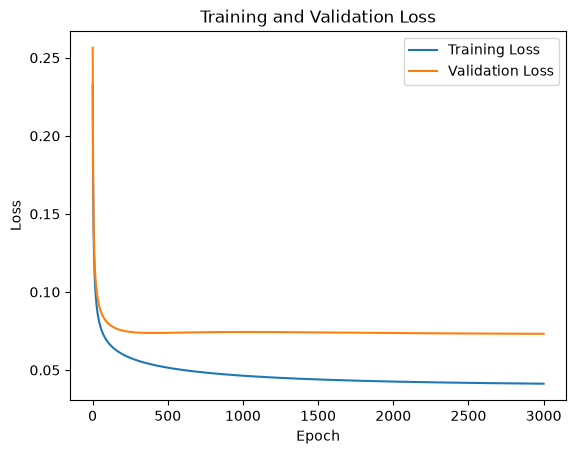

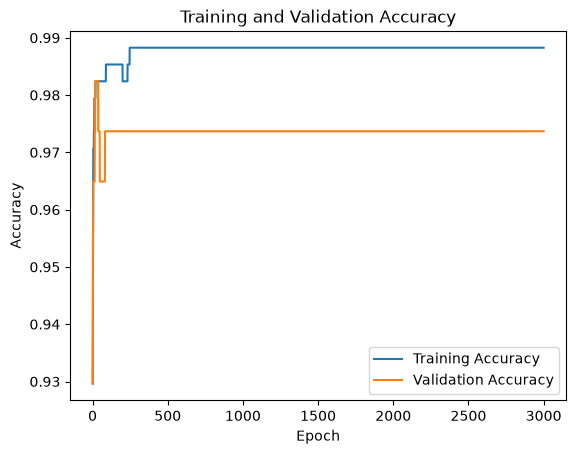

In [639]:
import matplotlib.pyplot as plt
besthistory=oldvalues[bestlambda]
epochnumbers=np.arange(1,epochs+1)
plt.plot(epochnumbers,besthistory["trainloss"], label="Training Loss")
plt.plot(epochnumbers,besthistory["valloss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.plot(epochnumbers,besthistory["trainaccuracy"], label="Training Accuracy")
plt.plot(epochnumbers,besthistory["valaccuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

Both training and validation losses decrease as the number of epochs increases and then they stablize (as they become nearly unchanged). This indicates that the model is learning and approaching convergence.

Training and validation accuracy increase and then they stablize (as they become nearly unchanged). The similar performance on both datasets indicates that the model generalizes well.

In [640]:
learning_rates=[0.01,0.1,1,5,20]
lam=0.01
epochs=1000
learning_rate_results = []
for ss in learning_rates:
    w=np.zeros(X_tr_bias.shape[1])
    for epoch in range(epochs):
        gradient=compute_gradient(X_tr_bias, y_tr,w,lam)
        w=w-ss*gradient
    finalloss = compute_data_loss(X_tr_bias, y_tr, w)

    learning_rate_results.append({
        "Learning Rate (step size)": ss,
        "Final Training Loss": finalloss
    })

learningratetable = pd.DataFrame(learning_rate_results)
print(learningratetable.round(4))

   Learning Rate (step size)  Final Training Loss
0                       0.01               0.1052
1                       0.10               0.0729
2                       1.00               0.0711
3                       5.00               0.0711
4                      20.00               0.0698


A small learning rate (step size=0.01) results in slower learning, while learning rates 0.1, 1 and 5 achieve lower training losses. A learning rate of 20 performs poorly, indicating that the learning rate is too large

In [641]:
lam=0
epochs=20000
eta=0.5
w=np.zeros(X_tr_bias.shape[1])
weightnorms=[]
traininglosses=[]
for epoch in range(epochs):
    gradient=compute_gradient(X_tr_bias,y_tr,w,lam)
    w=w-eta*gradient
    weightnorms.append(np.linalg.norm(w[1:]))
    traininglosses.append(compute_data_loss(X_tr_bias,y_tr,w))
print("Final weight norm:", weightnorms[-1])
print("Final training loss:", traininglosses[-1])

Final weight norm: 19.07910409109684
Final training loss: 0.011458238949846756


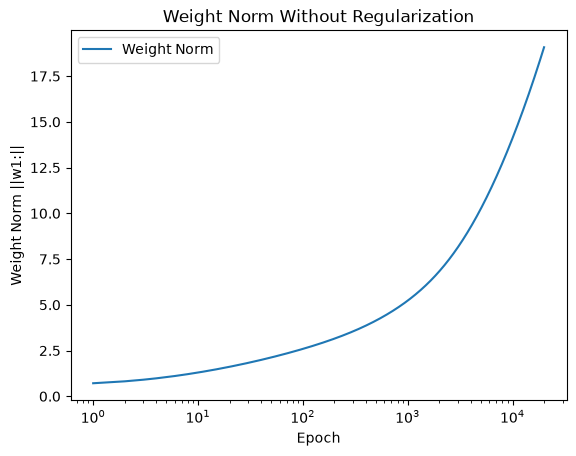

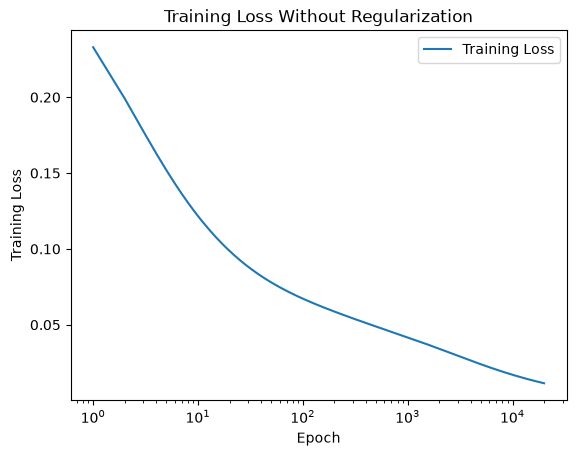

In [642]:
epoch_numbers=np.arange(1,epochs+1)
plt.plot(epoch_numbers, weightnorms, label="Weight Norm")
plt.xlabel("Epoch")
plt.ylabel("Weight Norm ||w1:||")
plt.title("Weight Norm Without Regularization")
plt.xscale("log")
plt.legend()
plt.show()

plt.plot(epoch_numbers, traininglosses, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Without Regularization")
plt.xscale("log")
plt.legend()
plt.show()

The training set appears to be linearly separable because the weight norm keeps increasing while the training loss keeps decreasing as the number of epochs increases. This indicates that the model can continue improving the separation between the two classes by increasing the magnitude of its weights

For linearly separable data, the logistic loss can approach zero by continuously increasing the magnitude of the weights in a direction that correctly separates the classes. However, no finite weight vector achieves exactly zero loss, so the unregularized objective does not have a finite minimizer

L2 regularization adds a penalty on large weights, discouraging them from growing. This helps produce a finite solution and prevents the weights from increasing indefinitely


In [643]:
from sklearn.linear_model import LogisticRegression
lambdas=[0,1e-3,1e-2,1e-1,1]
sklearn_results={}
sklearn_models={}
for lam in lambdas:
    if lam==0:
        model=LogisticRegression(penalty=None,max_iter=100000)
    else:
        C=1/(lam*N)
        model=LogisticRegression(C=C,penalty='l2',max_iter=100000 )
    model.fit(X_tr_std, y_tr)
    trainpred=model.predict(X_tr_std)
    valpred=model.predict(X_va_std)
    trainacc=np.mean(trainpred==y_tr)
    valacc=np.mean(valpred==y_va)
    sklearn_models[lam]=model
    sklearn_results[lam] = {"trainaccuracy": trainacc,
        "valaccuracy": valacc
    }
    print("Lambda:", lam)
    if lam==0:
        print("C:None")
    else:
        print("C:",1/(lam*N))
    print("Training accuracy:", trainacc)
    print("Validation accuracy:", valacc)
    print("\n")


Lambda: 0
C:None
Training accuracy: 1.0
Validation accuracy: 0.9649122807017544


Lambda: 0.001
C: 2.9325513196480935
Training accuracy: 0.9882697947214076
Validation accuracy: 0.9736842105263158


Lambda: 0.01
C: 0.29325513196480935
Training accuracy: 0.9853372434017595
Validation accuracy: 0.9736842105263158


Lambda: 0.1
C: 0.029325513196480937
Training accuracy: 0.9736070381231672
Validation accuracy: 0.9736842105263158


Lambda: 1
C: 0.002932551319648094
Training accuracy: 0.9384164222873901
Validation accuracy: 0.956140350877193




/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklea

In [644]:
lam=0.01
epochs=100000
eta=0.5
w=np.zeros(X_tr_bias.shape[1])
for epoch in range(epochs):
    gradient=compute_gradient( X_tr_bias,y_tr,w,lam)
    w=w-eta*gradient


In [645]:
lam=0.01
C=1/(lam*N)
smodel=LogisticRegression(C=C,penalty='l2',tol=1e-12,max_iter=100000)
smodel.fit(X_tr_std,y_tr)
sklearn_models[0.01]=smodel


/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [646]:
smodel=sklearn_models[0.01]
# Combine intercept and feature coefficients
wsklearn=np.concatenate((smodel.intercept_,smodel.coef_.ravel()))
relativeerror=np.linalg.norm(w-wsklearn)/max(np.linalg.norm(w),np.linalg.norm(wsklearn),1e-12)
print("My weights:")
print(w)
print("\nSklearn weights:")
print(wsklearn)
print("\nRelative weight error:", relativeerror)

if relativeerror<1e-4:
    print("Passed, relative error < 1e-4")
else:
    print("Failed")
print("\n")
mytestpred=(sigmoid(X_te_bias@w)>=0.5).astype(int)
sklearntestpred=smodel.predict(X_te_std)
if np.array_equal(mytestpred, sklearntestpred):
    print("Identical predictions")
else:
    print("Not identical predictions")

mytestaccuracy=np.mean(mytestpred == y_te)
sklearntestaccuracy=np.mean(sklearntestpred == y_te)
print("My Model test accuracy:",mytestaccuracy)
print("Sklearn test accuracy:",sklearntestaccuracy)


My weights:
[-0.42381639  0.45272781  0.4263065   0.43913875  0.43804957  0.29735916
 -0.02913228  0.48050766  0.6841554  -0.06778635 -0.25009878  0.51799217
  0.00371987  0.3139665   0.43284878  0.10062269 -0.37107719 -0.04554002
  0.25970856 -0.07377749 -0.40369869  0.60473948  0.89740174  0.53914397
  0.55938958  0.48909878  0.05929756  0.45633732  0.51856858  0.58966179
 -0.00755816]

Sklearn weights:
[-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956  0.29735929
 -0.02913226  0.48050726  0.68415511 -0.06778639 -0.25009845  0.51799241
  0.00372002  0.31396622  0.43284867  0.10062251 -0.37107717 -0.04553991
  0.25970891 -0.07377761 -0.40369878  0.60473964  0.89740166  0.53914392
  0.55938939  0.48909906  0.05929757  0.45633758  0.51856848  0.58966202
 -0.00755869]

Relative weight error: 5.333921461142484e-07
Passed, relative error < 1e-4


Identical predictions
My Model test accuracy: 0.9824561403508771
Sklearn test accuracy: 0.9824561403508771


The gradient descent model's weights and scikit-learn's weights closely match each other with relative error less than 1e-4, and the test predictions agrees 

In [647]:
Cvalues = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
Cresults = []
for C in Cvalues:
    model = LogisticRegression(C=C,penalty='l2',max_iter=100000)
    model.fit(X_tr_std, y_tr)
    trainacc=model.score(X_tr_std, y_tr)
    valacc=model.score(X_va_std, y_va)
    testacc=model.score(X_te_std, y_te)
    Cresults.append({
        "C": C,
        "Train Accuracy": trainacc,
        "Validation Accuracy": valacc,
        "Test Accuracy": testacc
    })
Ctable = pd.DataFrame(Cresults)
print(Ctable.round(4))

/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklea

          C  Train Accuracy  Validation Accuracy  Test Accuracy
0     0.001          0.8798               0.9035         0.8684
1     0.010          0.9501               0.9649         0.9474
2     0.100          0.9795               0.9825         0.9825
3     1.000          0.9883               0.9737         0.9737
4    10.000          0.9971               0.9649         0.9649
5   100.000          1.0000               0.9561         0.9561
6  1000.000          1.0000               0.9474         0.9561


/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


The results show that increasing the value of C, increases training accuracy because the regularization becomes weaker (lambda decrease), allowing the model to fit the training data more closely.

For C= 0.001, strong regularization may lead to underfitting, resulting in lower training, validation, and test accuracy.

The highest validation accuracy is at C=0.1, with 0.9795 training accuracy, 0.9825 validation accuracy, and 0.9825 test accuracy.

For larger values (C>=100), training accuracy continues to increase, reaching 1.0. However, validation and test accuracy decrease, which may indicate overfitting.

Therefore, C=0.1 provides the best performance among the tested values.

In [648]:
import time
C=1/(0.01*N)
solvers=['lbfgs', 'liblinear', 'saga']
solverresults = {}
for solver in solvers:
    model=LogisticRegression(C=C,penalty='l2',solver=solver,max_iter=100000,tol=1e-12,random_state=42)
    start=time.perf_counter()
    model.fit(X_tr_std, y_tr)
    tottime=time.perf_counter()-start
    coefficients = np.concatenate((model.intercept_,model.coef_.ravel()))
    solverresults[solver]={
        "coefficients": coefficients,
        "iterations": model.n_iter_[0],
        "time": tottime
    }
solvertable = pd.DataFrame([
    {
        "Solver": solver,
        "Iterations": result["iterations"],
        "Time (s)": result["time"],
        "Coefficients": result["coefficients"]
    }
    for solver, result in solverresults.items()
])

print(solvertable.to_string(index=False))

/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/asmaa/myenv/lib/python3.12/site-packages/sklea

   Solver  Iterations  Time (s)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           Coefficients
    lbfgs          29  0.053032 [-0.42381668531129013, 0.4527281364018039, 0.4263066749137461, 0.4391390115491478, 0.43804955881010965, 0.2973592916609872, -0.029132256525508285, 0.48050726326579396, 0.6841551147966706, -0.06778638790213394, -0.25009844716356516, 0.5179924147584597, 0.00372002255098427, 0.31396621746264

The three solvers (lbfgs, liblinear, and saga) were compared using the same regularization parameter C=1/(0.01×N).Their coefficients, number of iterations, and execution times were recorded to compare their optimization performance

saga produced coefficients closest to lbfgs

liblinear converged in the fewest iterations (10)

liblinear had the shortest training time 

Although liblinear was the fastest, its coefficients differed more from the other solvers because it penalizes the intercept, unlike lbfgs and saga.

The liblinear solver penalizes the intercept (because it represents the intercept using additional synthetic feature that is added to the input features). The coefficient of this synthetic feature represents the intercept which means the intercept is included in the regularization penalty, unlike the other two solvers. As a result, the intercept is encouraged to be closer to zero, which can affect the decision boundary

In [649]:
# Calculate probabilities on the test set
test_probs = sigmoid(X_te_bias@w)
# Predict using threshold = 0.5
test_pred = (test_probs >= 0.5).astype(int)
cm=confusion_matrix(y_te,test_pred,2)
print("Test Confusion Matrix:")
print(cm)
# Calculate classification metrics
metrics=classification_metrics(cm)
print("Precision:",metrics["precision"][1])
print("Recall:",metrics["recall"][1])
print("F1:",metrics["f1"][1])


Test Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1: 0.975609756097561


At a threshold of 0.5:

The model correctly classified all 72 benign cases and 40 out of 42 malignant cases

It achieved a precision of 1.0, meaning that all cases predicted as malignant were actually malignant 

The recall is 0.9524 , meaning that the model detected 95.24% of the actual malignant cases, while missing 2 cases

In [650]:
# Calculate probabilities on the validation set
val_probs = sigmoid(X_va_bias @ w)

def roc_curve_scratch(ytrue, scores):
    sortedind = np.argsort(-scores) # np.argsort(-scores) gives us the indices that would sort the scores in descending order.
    ysorted=ytrue[sortedind]
    sortedscores=scores[sortedind]
    P=np.sum(ytrue==1) # P = total number of actual malignant patients. p=TP + FN: Total number of actual malignant cases
    N=np.sum(ytrue==0) # N = total number of actual benign patients.
    TP=0
    FP=0
    tpr=[0]
    fpr=[0]
    i = 0
    while i<len(sortedscores):
        threshold = sortedscores[i]
        # Process all samples with the same score
        while i<len(sortedscores) and sortedscores[i]==threshold:
            if ysorted[i]==1:
                TP+=1
            else:
                FP+=1
            i+=1
        tpr.append(TP/P)
        fpr.append(FP/N)

    return np.array(fpr),np.array(tpr)

In [651]:
fpr,tpr=roc_curve_scratch(y_va, val_probs)
from sklearn.metrics import roc_auc_score
auc=np.trapezoid(tpr,fpr)
print("Scratch AUC:",auc)
sklearnauc=roc_auc_score(y_va, val_probs)
print("Sklearn AUC:", sklearnauc)
difference = abs(auc - sklearnauc)
print("Absolute difference:", difference)
if difference<1e-6:
    print("Passed, difference < 1e-6")
else:
    print("Failed, difference >= 1e-6")

Scratch AUC: 0.9957418932197839
Sklearn AUC: 0.9957418932197838
Absolute difference: 1.1102230246251565e-16
Passed, difference < 1e-6


Verfication check: The abs differnece is less than 1e-6

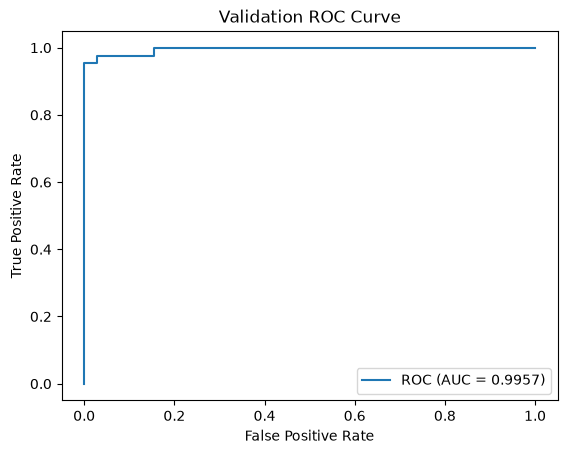

In [652]:
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.4f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.show()


The ROC curve is very close to the upperleft corner, indicating a high true positive rate and a low false positive rate. the AUC is approximately 0.9957. This indicates that the model has high ability to distinguish between malignant and benign cases across different classification thresholds

In [653]:
malprob=val_probs[y_va==1]
largestthrshld=np.min(malprob)
print("Selected threshold:",largestthrshld)

valpredth=(val_probs>=largestthrshld).astype(int)
valcmth=confusion_matrix(y_va, valpredth, 2)
valmetricsth=classification_metrics(valcmth)
print("\nValidation Confusion Matrix:")
print(valcmth)
print("Validation Recall:", valmetricsth["recall"][1])

Selected threshold: 0.14602532432073892

Validation Confusion Matrix:
[[60 11]
 [ 0 43]]
Validation Recall: 1.0


The largest Threshold is the minimum predicted probalilty among malignant patients becuase validation recall =1 means Tp/Tp+Fn =1 so Fn should be 0, meaning all actual malginant patients should be predicted correctly. so we filter the malignant patients and see the minimum probability among them and then this is the max threshold, becuse threshold less than this meaning it wont be the largest, and bigger than this means it will not classify this patient as malignant so it will result fn

In [654]:
# Apply the selected threshold to the test set
testpredth=(test_probs>=largestthrshld).astype(int)

cmth=confusion_matrix(y_te,testpredth,2)
metricsth=classification_metrics(cmth)
print("\nTest Confusion Matrix at the selected threshold:")
print(cmth)
print("Precision:",metricsth["precision"][1])
print("Recall:",metricsth["recall"][1])
print("F1:",metricsth["f1"][1])


Test Confusion Matrix at the selected threshold:
[[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762
F1: 0.9213483146067415


In [655]:
thresholdtable = pd.DataFrame({
    "Threshold": [0.5, largestthrshld],
    "Precision": [metrics["precision"][1], metricsth["precision"][1]],
    "Recall": [metrics["recall"][1], metricsth["recall"][1]],
    "F1-score": [metrics["f1"][1], metricsth["f1"][1]]
})

print(thresholdtable.round(4))

   Threshold  Precision  Recall  F1-score
0      0.500     1.0000  0.9524    0.9756
1      0.146     0.8723  0.9762    0.9213


At threshold 0.5, precision is higher (1.0000), meaning there are no false positives, but recall is slightly lower (0.9524).

At threshold 0.1460, recall increases to 0.9762, meaning fewer malignant patients are missed, but precision decreases to 0.8723 because more benign patients are incorrectly classified as malignant.

False negative means a malginant patient was predicted as benign, its dangeroud because the patient need treatment but doesnt know yet.

False positive means a benign patient was predicted as malignant, which may lead to unnecessary follow-up tests that can cause stress and anxiety. 

False negatives are particularly costly, so achieving high recall is important.

We shoudnt completely trust this threshold becuse it is selected according to 43 positive patients (in the validation set), so it may not achieve recall=1 on unseen data

In [656]:
X_tr_2=X_tr[:,:2]
X_va_2=X_va[:,:2]
X_te_2=X_te[:,:2]
# print("Training shape:", X_tr_2.shape)
# print("Validation shape:", X_va_2.shape)
# print("Testing shape:", X_te_2.shape)
scaler2=Standardizer()
scaler2.fit(X_tr_2)
X_tr_2_std=scaler2.transform(X_tr_2)
X_va_2_std=scaler2.transform(X_va_2)
X_te_2_std=scaler2.transform(X_te_2)
X_tr_2_bias=add_bias(X_tr_2_std)
X_va_2_bias=add_bias(X_va_2_std)
X_te_2_bias=add_bias(X_te_2_std)
# print("Training bias shape:", X_tr_2_bias.shape)
# print("Validation bias shape:", X_va_2_bias.shape)
# print("Testing bias shape:", X_te_2_bias.shape)

"Derive that the weights in the original (unstandardized) coordinates are w_j^orig = w_j/σ_j and w0^orig =
w0 − Σ_j w_j μ_j/σ_j"

The Standardize eqn
xj(std)=(xj(orig)−μj)/σj    (eqn 1)

z=w0(orig)+w1(orig)x1(orig)+w2(orig)x2(orig)   (eqn 2)
z=w0+w1x1(std)+w2x2(std)   (eqn 3)

Substitute eqn 1 in eqn 3:
z=w0+w1*((x1(orig)−μ1)/σ1)+w2*((x2(orig)−μ2)/σ2)
=w0+w1x1(orig)/σ1−w1μ1/σ1+w2x2(orig)/σ2−w2μ2/σ2

rearranging (by taking constants together)
=w0−w1μ1/σ1-w2μ2/σ2+w1x1(orig)/σ1+w2x2(orig)/σ2

compare with eqn 2
w0(orig)= w0−w1μ1/σ1-w2μ2/σ2 = w0−Σw_j*μ_j/σ_j
w1(orig)= w1/σ1
w2(orig)= w2/σ2


In [657]:
lam=0
eta=0.5
epochs=5000
w2=np.zeros(X_tr_2_bias.shape[1])
for epoch in range(epochs):
    gradient = compute_gradient(X_tr_2_bias, y_tr, w2, lam)
    w2=w2-eta*gradient
print("New weights (standardized.):", w2)

New weights (standardized.): [-0.7271724   3.65679417  1.00987153]


The New weights (standardized) are:

bias=-0.7271724

w1=3.65679417

w2= 1.00987153

In [658]:
w2orig=w2[1:]/scaler2.std
w0_orig=w2[0]-np.sum(w2[1:]*scaler2.mean/scaler2.std)
worig=np.concatenate(([w0_orig], w2orig))
print("original (unstandardized) weights:",worig)

original (unstandardized) weights: [-19.64344417   1.01746116   0.23190058]


original (unstandardized) weights are:

bias=-19.64344417   

w1=1.01746116  

w2=0.23190058

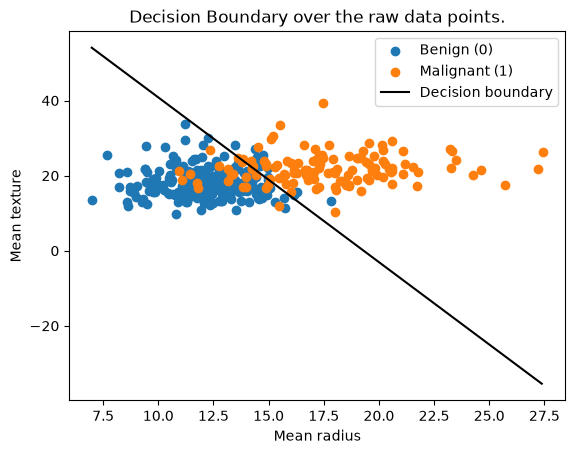

In [659]:
# Generate x values for the line
# x_line = np.linspace(X_tr_2[:, 0].min(), X_tr_2[:, 0].max(), 200)
xline = np.arange(X_tr_2[:, 0].min(), X_tr_2[:, 0].max(), 0.1)
# Calculate corresponding y values
yline=-(worig[0]+worig[1]*xline)/worig[2]
# Plot raw data points
plt.scatter(X_tr_2[y_tr==0,0],X_tr_2[y_tr==0,1],label="Benign (0)")
plt.scatter(X_tr_2[y_tr==1,0],X_tr_2[y_tr==1,1],label="Malignant (1)")
# Plot decision boundary
plt.plot(xline, yline,label="Decision boundary",color='black')
plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.title("Decision Boundary over the raw data points.")
plt.legend()


The plot shows the decision line over the raw training data points as it separates the benign and malignant classes


In [660]:
scoresstd=X_tr_2_bias@w2 # Scores using standardized features and weights
scoresorig=add_bias(X_tr_2)@worig # Scores using original features and converted weights

difference = np.max(np.abs(scoresstd-scoresorig)) # Calculate maximum absolute difference
print("Maximum score difference:", difference)
if difference<1e-9:
    print("Scores agree to 1e-9")
else:
    print("Scores do not agree to 1e-9")

Maximum score difference: 3.552713678800501e-15
Scores agree to 1e-9


We calculate the absolute difference between the two scores for each sample. Then we get the maximum(worst) among them and compare them with 1e-9

The output verifies that scores computed with the standardized and with the converted weights agree to 1e-9.


In [661]:
X_train, X_val, X_test, y_train, y_val, y_test = digits_split
X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("Training with bias:", X_train_bias.shape)
print("Validation with bias:", X_val_bias.shape)
print("Testing with bias:", X_test_bias.shape)


Training: (1077, 64) (1077,)
Validation: (360, 64) (360,)
Testing: (360, 64) (360,)
Training with bias: (1077, 65)
Validation with bias: (360, 65)
Testing with bias: (360, 65)


In [662]:
def softmax(S):
    m = np.max(S,axis=1,keepdims=True)
    S_shifted = S - m
    exp_scores = np.exp(S_shifted)

    P = exp_scores / np.sum(exp_scores,axis=1,keepdims=True)
    return P
def cross_entropy_loss(S,y):
    m = np.max(S,axis=1,keepdims=True)
    log_sum_exp = m[:,0] + np.log(np.sum(np.exp(S - m),axis=1))
    correct_scores = S[np.arange(len(y)), y]
    losses = log_sum_exp - correct_scores
    return np.mean(losses)
#Regularized entropy -> takes X_bias
def softmax_loss(X_bias, y, W, lam):
    S = X_bias @ W
    data_loss = cross_entropy_loss(S, y)
    reg_loss = (lam / 2) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss


# Deriving the Softmax Gradient

The loss function -> L(W) = -(1/N) * sum_i (log Pi.yi) + (lambda/2) * norm(W1:)

* First part -(1/N) * sum_i (log Pi.yi) :

it is given that dl/ds_i_k = Pi_k - Yi_k  ===> which tells the derivative of the loss with respect to each score

So, for all samples, dL / dS = (1/N) * P-Y

And since S = X_bias * W, Applying the chain rule gives us ===> dL / dW = X_bias.T * dL/dS

Therefore, dL / dW = (1/N) * X_bias.T * (P-Y)

* Second part (lambda/2) * norm(W1:) :

||w1:||^2 = sum_j(sum_i(W_j_i^2))

Then, Lreg = (lambda/2) * sum_j(sum_i(W_j_i^2))

Diffrentiating with respect to one weight gives: dL /dW_j_i = (lambda/2) * 2 * W_j_i = lambda * W_j_i

And since we regularize weights without the bias => dL/dW = lambda * [0 W1:]T

* Combining both derivatives => dL/dW = (1/N) * X_bias.T * (P-Y) + lambda * [0 W1:]T


In [663]:
def softmax_gradient(X_bias, y, W, lam):
    N = len(y)
    #Calculate scores -> we ahve to calculate scores every time as the weights are being updated
    S = X_bias @ W
    P = softmax(S)
    Y = np.zeros_like(P)
    Y[np.arange(N), y] = 1
    grad = (X_bias.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]
    return grad

In [664]:
#testing softmax invariance -> softmax(s + c·1) = softmax(s)
s1 = np.array([[1.0, 2.0, 3.0]])
s2 = np.array([[101.0, 102.0, 103.0]])
print(softmax(s1))
print(softmax(s2))

[[0.09003057 0.24472847 0.66524096]]
[[0.09003057 0.24472847 0.66524096]]


* So, adding a constant to the scores won't affect the probablities

In [665]:
#No overflow test -> because we normalized the scores
scores = np.array([[1000.0, 1001.0, 1002.0]])
probabilities = softmax(scores)
print(probabilities)
print("Sum:", np.sum(probabilities))

[[0.09003057 0.24472847 0.66524096]]
Sum: 0.9999999999999999


* No overflow happened as we normalized the scores (Subtracted the maximum score of each image)

In [666]:
# W=0 test -> the regularization term = 0 , pure cross entropy loss
W_zero = np.zeros((65, 10))
loss = softmax_loss(
    X_train_bias,
    y_train,
    W_zero,
    lam=0.1
)
print("Calculated loss:", loss)
print("Expected loss:", np.log(10))

Calculated loss: 2.3025850929940463
Expected loss: 2.302585092994046


* If weights = 0 ,This means lambda is multiplied by 0 which makes the regularization term vanishes causing pure cross entropy loss (No weights to penelize)

In [667]:
def grad_check2(X_bias, y, lam=0.1):
    rng = np.random.default_rng(42)
    W = rng.normal(0, 0.01, size=(X_bias.shape[1], 10))
    analytical_grad = softmax_gradient(X_bias, y, W, lam)
    # Selecting 100 random weight positions
    indices = rng.choice(W.size, size=100, replace=False)
    epsilon = 1e-5
    errors = []
    for idx in indices:
        i, j = np.unravel_index(idx, W.shape)

        W_plus = W.copy()
        W_plus[i, j] += epsilon
        loss_plus = softmax_loss(X_bias, y, W_plus, lam)
        W_minus = W.copy()
        W_minus[i, j] -= epsilon
        loss_minus = softmax_loss(X_bias, y, W_minus, lam)
        numerical_grad = (loss_plus - loss_minus) / (2 * epsilon)
        analytical = analytical_grad[i, j]
        error = abs(numerical_grad - analytical) / max(
            1e-8, abs(numerical_grad) + abs(analytical)
        )
        errors.append(error)
    max_error = max(errors)
    print("Maximum relative error:", max_error)
    assert max_error < 1e-6, "Gradient check failed!"
grad_check2(X_train_bias, y_train, lam=0.1)

Maximum relative error: 2.2536881201127445e-07


* Gradient check passed ,as relative error is < 1e-6.

In [668]:

def train_softmax(X_train_bias, y_train,
                  X_val_bias, y_val,
                  eta, lam, epochs=100, batch_size=64):
    N = len(y_train)
    K = len(np.unique(y_train))
    W = np.zeros((X_train_bias.shape[1], K))
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    for epoch in range(epochs):
        indices = np.random.permutation(N)
        X_shuffled = X_train_bias[indices]
        y_shuffled = y_train[indices]
        # Mini-batch training
        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
            grad = softmax_gradient(
                X_batch, y_batch, W, lam
            )
            W -= eta * grad
        # batches training ends here(for this epoch) -> all weights are updated for this epoch
        train_loss = softmax_loss(
            X_train_bias, y_train, W, lam
        )
        val_loss = softmax_loss(
            X_val_bias, y_val, W, lam
        )
        train_pred = np.argmax(
            softmax(X_train_bias @ W), axis=1
        )
        train_acc = np.mean(train_pred == y_train)
        val_pred = np.argmax(
            softmax(X_val_bias @ W), axis=1
        )
        val_acc = np.mean(val_pred == y_val)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)
    return W, train_losses, val_losses, train_accuracies, val_accuracies


In [669]:
learning_rates = [0.01, 0.1, 0.5, 1.0]
results = {}
for eta in learning_rates:
    np.random.seed(42)
    W, train_losses, val_losses ,train_accs, val_accs= train_softmax(
        X_train_bias,
        y_train,
        X_val_bias,
        y_val,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )
    results[eta] = {
    "W": W,
    "train_losses": train_losses,
    "val_losses": val_losses,
    "train_accs": train_accs,
    "val_accs": val_accs
}

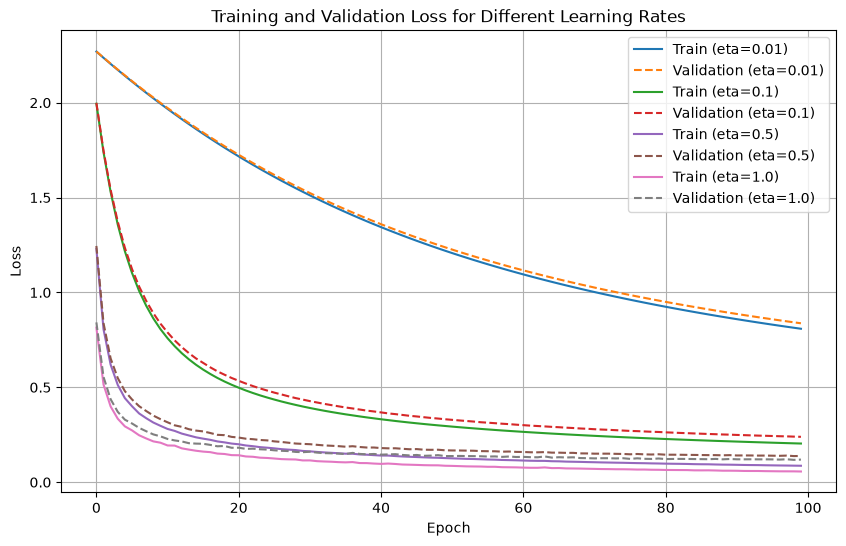

In [670]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for eta in learning_rates:
    plt.plot(
        results[eta]["train_losses"],
        label=f"Train (eta={eta})"
    )
    plt.plot(
        results[eta]["val_losses"],
        linestyle="--",
        label=f"Validation (eta={eta})"
    )
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss for Different Learning Rates")
plt.legend()
plt.grid()
plt.show()

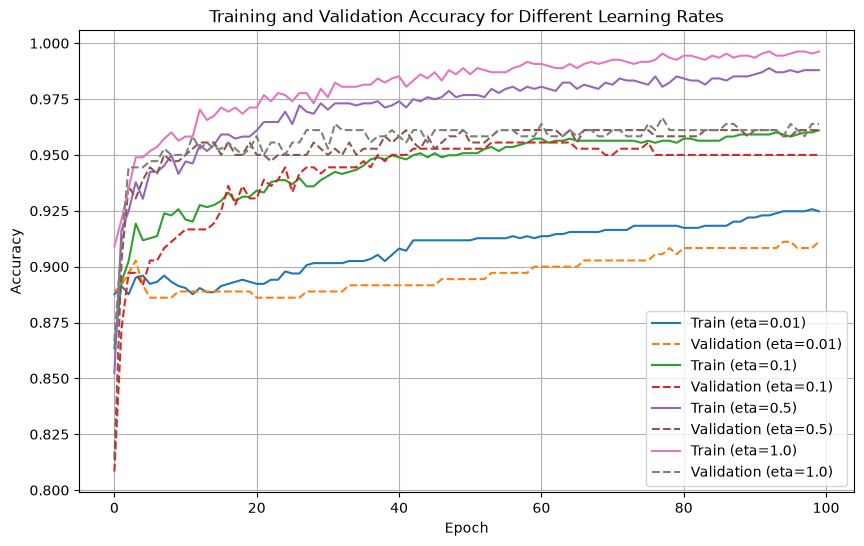

In [671]:
plt.figure(figsize=(10, 6))
for eta in learning_rates:
    plt.plot(
        results[eta]["train_accs"],
        label=f"Train (eta={eta})"
    )
    plt.plot(
        results[eta]["val_accs"],
        linestyle="--",
        label=f"Validation (eta={eta})"
    )
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy for Different Learning Rates")
plt.legend()
plt.grid()
plt.show()

In [672]:
# Final results for each learning rate
for eta in learning_rates:
    print(f"\nLearning rate: {eta}")
    print(f"Training loss:     {results[eta]['train_losses'][-1]:.4f}")
    print(f"Validation loss:   {results[eta]['val_losses'][-1]:.4f}")
    print(f"Training accuracy: {results[eta]['train_accs'][-1]:.4f}")
    print(f"Validation accuracy: {results[eta]['val_accs'][-1]:.4f}")


Learning rate: 0.01
Training loss:     0.8086
Validation loss:   0.8374
Training accuracy: 0.9248
Validation accuracy: 0.9111

Learning rate: 0.1
Training loss:     0.2038
Validation loss:   0.2391
Training accuracy: 0.9610
Validation accuracy: 0.9500

Learning rate: 0.5
Training loss:     0.0867
Validation loss:   0.1383
Training accuracy: 0.9879
Validation accuracy: 0.9611

Learning rate: 1.0
Training loss:     0.0564
Validation loss:   0.1192
Training accuracy: 0.9963
Validation accuracy: 0.9639


In [673]:
best_eta = min(
    learning_rates,
    key=lambda eta: results[eta]["val_losses"][-1]
)
print("Best learning rate:", best_eta)
print("Best validation loss:",
      results[best_eta]["val_losses"][-1])

Best learning rate: 1.0
Best validation loss: 0.11920121080117577


With eta=0.01, the model has a relatively high final training loss (0.8086) and validation loss (0.8374), with validation accuracy of 91.11%. This indicates that the model is under-trained after 100 epochs because the learning rate is too small.

Increasing the learning rate improves convergence and classification performance.

The learning rate eta=1.0 achieves the lowest final validation loss (0.1192) and the highest validation accuracy (96.39%) among the tested values.

* Therefore, I select best learning rate =1.0 

In [674]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]
lambda_results = {}
for lam in lambdas:
    np.random.seed(42)
    W, train_losses, val_losses,train_accs, val_accs = train_softmax(
        X_train_bias,
        y_train,
        X_val_bias,
        y_val,
        eta=best_eta,
        lam=lam,
        epochs=100,
        batch_size=64
    )
    val_accuracy = val_accs[-1]
    lambda_results[lam] = {
        "W": W,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_accuracy": val_accuracy
    }
    print(f"Lambda: {lam}")
    print(f"Validation loss: {val_losses[-1]:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print("-----------------------------")

Lambda: 0
Validation loss: 0.1192
Validation accuracy: 0.9639
-----------------------------
Lambda: 0.0001
Validation loss: 0.1505
Validation accuracy: 0.9611
-----------------------------
Lambda: 0.001
Validation loss: 0.3033
Validation accuracy: 0.9639
-----------------------------
Lambda: 0.01
Validation loss: 0.7947
Validation accuracy: 0.9389
-----------------------------
Lambda: 0.1
Validation loss: 1.8040
Validation accuracy: 0.6056
-----------------------------


In [675]:
best_lam = max(
    lambdas,
    key=lambda lam: (lambda_results[lam]["val_accuracy"], lam)
)
best_W = lambda_results[best_lam]["W"]
test_scores = X_test_bias @ best_W
test_probs = softmax(test_scores)
test_predictions = np.argmax(test_probs, axis=1)
test_accuracy = np.mean(test_predictions == y_test)
print("Best lambda: ",best_lam)
print("Test accuracy:", test_accuracy)

Best lambda:  0.001
Test accuracy: 0.9611111111111111



* My Softmax implementation achieves its highest validation accuracy of 96.39%, with a tie between lambda=0 and lambda=0.001 .So, taking the highest best lambda is 0.001.


* At lambda=0.1, my implementation's accuracy drops significantly, indicating that this regularization value is too strong for my training setup.

In [676]:
from sklearn.linear_model import LogisticRegression

In [677]:
sklearn_results = {}
for lam in lambdas:
    if lam == 0:
        C = 1e12
    else:
        C = 1 / (lam * len(y_train))
    model = LogisticRegression(
        C=C,
        max_iter=10000
    )
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_acc = np.mean(val_pred == y_val)
    test_pred = model.predict(X_test)
    test_acc = np.mean(test_pred == y_test)
    sklearn_results[lam] = {
        "model": model,
        "C": C,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc,
        "test_predictions": test_pred
    }
    print(f"Lambda: {lam}")
    print(f"C: {C:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print("-----------------------------")

Lambda: 0
C: 1000000000000.0000
Validation accuracy: 0.9556
Test accuracy: 0.9556
-----------------------------


Lambda: 0.0001
C: 9.2851
Validation accuracy: 0.9750
Test accuracy: 0.9611
-----------------------------
Lambda: 0.001
C: 0.9285
Validation accuracy: 0.9722
Test accuracy: 0.9556
-----------------------------
Lambda: 0.01
C: 0.0929
Validation accuracy: 0.9472
Test accuracy: 0.9333
-----------------------------
Lambda: 0.1
C: 0.0093
Validation accuracy: 0.9028
Test accuracy: 0.8861
-----------------------------


* Scikit-learn achieves its highest validation accuracy of 97.50% at lambda=0.0001

In [678]:
print("Comparison: Own Softmax vs sklearn LogisticRegression")
for lam in lambdas:
    print(f"\nLambda: {lam}")
    print("Own validation accuracy:",
          f"{lambda_results[lam]['val_accuracy']:.4f}")
    print("sklearn validation accuracy:",
          f"{sklearn_results[lam]['val_accuracy']:.4f}")
    # Own test accuracy
    own_W = lambda_results[lam]["W"]
    own_test_pred = np.argmax(
        softmax(X_test_bias @ own_W),
        axis=1
    )
    own_test_acc = np.mean(own_test_pred == y_test)
    print("Own test accuracy:",
          f"{own_test_acc:.4f}")
    print("sklearn test accuracy:",
          f"{sklearn_results[lam]['test_accuracy']:.4f}")

Comparison: Own Softmax vs sklearn LogisticRegression

Lambda: 0
Own validation accuracy: 0.9639
sklearn validation accuracy: 0.9556
Own test accuracy: 0.9639
sklearn test accuracy: 0.9556

Lambda: 0.0001
Own validation accuracy: 0.9611
sklearn validation accuracy: 0.9750
Own test accuracy: 0.9611
sklearn test accuracy: 0.9611

Lambda: 0.001
Own validation accuracy: 0.9639
sklearn validation accuracy: 0.9722
Own test accuracy: 0.9611
sklearn test accuracy: 0.9556

Lambda: 0.01
Own validation accuracy: 0.9389
sklearn validation accuracy: 0.9472
Own test accuracy: 0.9222
sklearn test accuracy: 0.9333

Lambda: 0.1
Own validation accuracy: 0.6056
sklearn validation accuracy: 0.9028
Own test accuracy: 0.6389
sklearn test accuracy: 0.8861


* The manual model best lambda is 0.001 while that of the sklearn model is 0.0001.


In [679]:
# My best model
own_predictions = np.argmax(
    softmax(X_test_bias @ best_W),
    axis=1
)
# sklearn model corresponding to best lambda
sk_model_best = sklearn_results[best_lam]["model"]
sklearn_predictions = sk_model_best.predict(X_test)
agreement = np.mean(
    own_predictions == sklearn_predictions
)
print("Prediction agreement (%):", agreement * 100)

Prediction agreement (%): 99.44444444444444


* Taking the mean of the matching predictions:

* Prediction Agreement =99.44%

* This exceeds 97%, showing that both implementations produce nearly identical predictions on the test set (same prediction on approximately 358 out of 360 test images).

In [680]:
C_values = [0.1, 1, 10, 100]
C_sweep_results = {}
for C in C_values:
    model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)
    val_acc = np.mean(val_pred == y_val)
    test_acc = np.mean(test_pred == y_test)
    C_sweep_results[C] = {
        "model": model,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc
    }
    print(f"C: {C}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print("-----------------------------")

C: 0.1
Validation accuracy: 0.9500
Test accuracy: 0.9389
-----------------------------
C: 1
Validation accuracy: 0.9722
Test accuracy: 0.9556
-----------------------------
C: 10
Validation accuracy: 0.9639
Test accuracy: 0.9556
-----------------------------
C: 100
Validation accuracy: 0.9611
Test accuracy: 0.9556
-----------------------------


* C = 1 achieved the highest Validation accuracy (97.22%)

In [681]:
## Confusion matrix
test_scores = X_test_bias @ best_W
test_predictions = np.argmax(
    softmax(test_scores),
    axis=1
)
cm = confusion_matrix(
    y_test,
    test_predictions,
    K=10
)
print(cm)

[[35  0  0  0  1  0  0  0  0  0]
 [ 0 33  0  0  0  1  1  0  1  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  4  0  0  0  0  0  2 29  0]
 [ 0  0  0  0  2  0  0  0  1 33]]


In [682]:
metrics = classification_metrics(cm)
metrics_table = pd.DataFrame({
    "Digit": range(10),
    "Precision": metrics["precision"],
    "Recall": metrics["recall"],
    "F1-score": metrics["f1"]
})
print(metrics_table.round(4))
print("\nMacro averages:")
print(f"Precision: {metrics['macro_precision']:.4f}")
print(f"Recall:    {metrics['macro_recall']:.4f}")
print(f"F1-score:  {metrics['macro_f1']:.4f}")

   Digit  Precision  Recall  F1-score
0      0     1.0000  0.9722    0.9859
1      1     0.8919  0.9167    0.9041
2      2     1.0000  1.0000    1.0000
3      3     1.0000  1.0000    1.0000
4      4     0.9231  1.0000    0.9600
5      5     0.9737  1.0000    0.9867
6      6     0.9722  0.9722    0.9722
7      7     0.9474  1.0000    0.9730
8      8     0.9062  0.8286    0.8657
9      9     1.0000  0.9167    0.9565

Macro averages:
Precision: 0.9614
Recall:    0.9606
F1-score:  0.9604


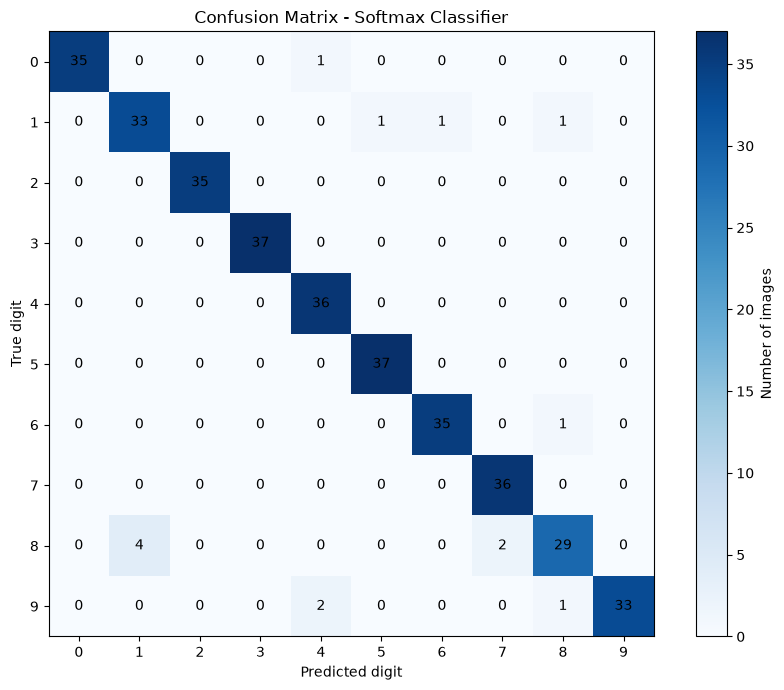

In [683]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title("Confusion Matrix - Softmax Classifier")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")
plt.tight_layout()
plt.show()

In [684]:
confused_pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((i, j, cm[i, j]))
confused_pairs.sort(key=lambda x: x[2], reverse=True)
print("Top 3 most confused pairs:")
for true_digit, predicted_digit, count in confused_pairs[:3]:
    print(
        f"True digit: {true_digit}, "
        f"Predicted digit: {predicted_digit}, "
        f"Count: {count}"
    )

Top 3 most confused pairs:
True digit: 8, Predicted digit: 1, Count: 4
True digit: 8, Predicted digit: 7, Count: 2
True digit: 9, Predicted digit: 4, Count: 2


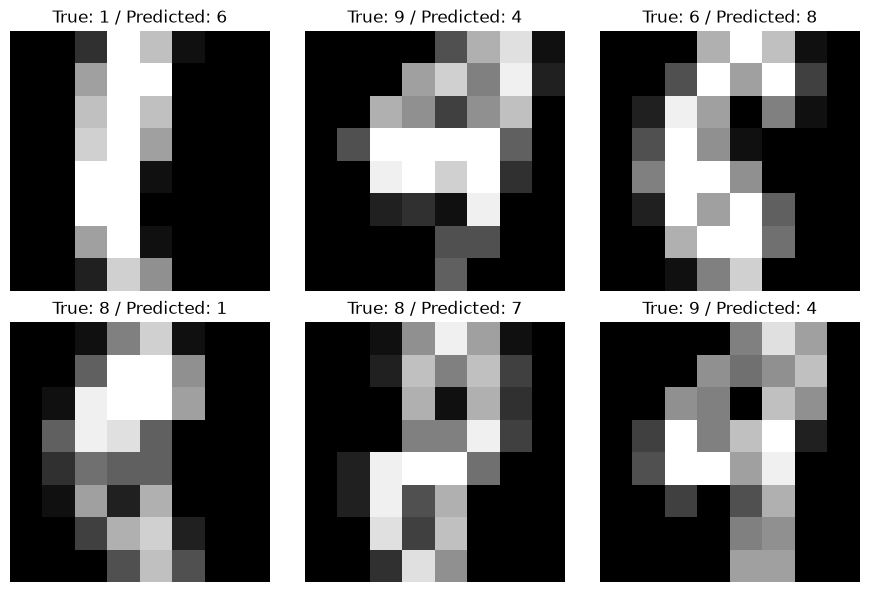

In [685]:
misclassified = np.where(y_test != test_predictions)[0]
selected_errors = misclassified[:6]
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for ax, idx in zip(axes.ravel(), selected_errors):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    ax.set_title(
        f"True: {y_test[idx]} / Predicted: {test_predictions[idx]}"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

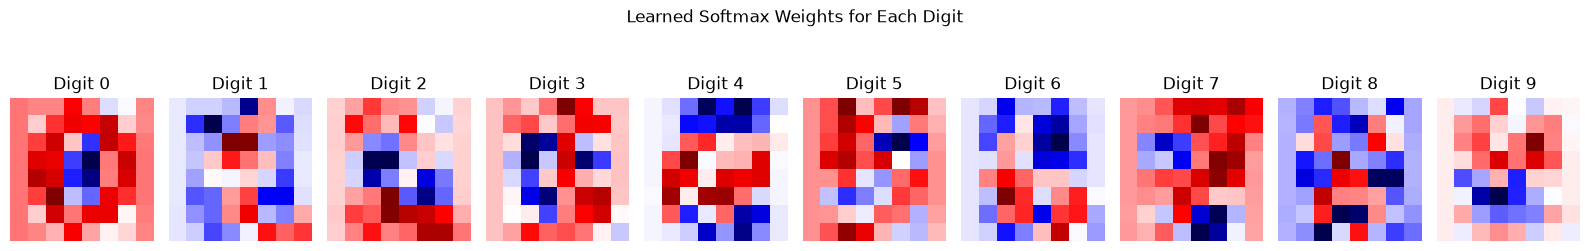

In [686]:
fig, axes = plt.subplots(1, 10, figsize=(16, 3))
for k in range(10):
    digit_weights = best_W[1:, k]
    weight_image = digit_weights.reshape(8, 8)
    axes[k].imshow(weight_image, cmap="seismic")
    axes[k].set_title(f"Digit {k}")
    axes[k].axis("off")
plt.suptitle("Learned Softmax Weights for Each Digit")
plt.tight_layout()
plt.show()

Digit 8 is the hardest class to recognize, having the lowest recall (82.86%) and F1-score (86.57%), with most of its errors being classified as digit 1 or 7. Digit 1 is also relatively difficult, with a precision of 89.19%, because some other digits are incorrectly predicted as 1. Digit 9 is sometimes confused with digits 4 and 8, while digit 6 is occasionally confused with digit 8. These errors make sense because the Softmax classifier is linear and uses fixed weights for individual pixel positions, so it cannot fully capture variations in complex shapes, and relationships between pixels.

#  Mathematical Proof that Softmax with K = 2 is Logistic regression 

For a Softmax classifier, the probability of class \(k\) is:
 
P( y= k | x_bias) = e^(x_bias.T * W_k) / sum_j (e^(x_bias.T * W_j)) 

we have only two classes: 0 and 1.

So, The Probability of Class 1 for example is :

P( y= 1 | x_bias) = e^(x_bias.T * W_1) / ( e^(x_bias.T * W_1) + e^(x_bias.T * W_0) ) 

= P( y= 1 | x_bias) = 1 /  e^(x_bias.T * W_0 - x_bias.T * W_1) + 1  ==> Dividing by e^(x_bias.T * W_1)

= P( y= 1 | x_bias) = 1 /  e^(- x_bias.T *( W_1 -  W_0)) + 1 ==> Taking (- x_bias.T) as Common Factor in the exponent


* That is equivalent to 1 / 1 + e^(- z) ==> Sigmoid function with z = x_bias.T *( W_1 -  W_0)

 P( y= 1 | x_bias) = Sigmoid (x_bias.T *( W_1 -  W_0))

* Which proves that two-class Softmax is equivalent to Logistic Regression.

In [687]:
X_bc_train, X_bc_val, X_bc_test, y_bc_train, y_bc_val, y_bc_test = breast_split
bc_scaler = Standardizer().fit(X_bc_train)
X_bc_test_std = bc_scaler.transform(X_bc_test)
X_bc_test_bias = add_bias(X_bc_test_std)

#Generating a random matrix
rng = np.random.default_rng(42)
W_binary = rng.normal(
    0, 0.12,
    size=(31, 2)
)
S_binary = X_bc_test_bias @ W_binary
P_softmax = softmax(S_binary)
p1_softmax = P_softmax[:, 1]

w_difference = W_binary[:, 1] - W_binary[:, 0]
z = X_bc_test_bias @ w_difference
p1_sigmoid = 1 / (1 + np.exp(-z))
differences = np.abs(p1_softmax - p1_sigmoid)
max_difference = np.max(differences)
print("Maximum probability difference:", max_difference)


Maximum probability difference: 2.220446049250313e-16


* Maximum difference < 10^-12. So, This confirms numerically that two-class Softmax is equivalent to Logistic Regression

In [688]:
X_iris_train, X_iris_val, X_iris_test, y_iris_train, y_iris_val, y_iris_test = iris_split
X_iris_train = X_iris_train[:, 2:4]
X_iris_val = X_iris_val[:, 2:4]
X_iris_test = X_iris_test[:, 2:4]
iris_scaler = Standardizer().fit(X_iris_train)
X_iris_train_std = iris_scaler.transform(X_iris_train)
X_iris_val_std = iris_scaler.transform(X_iris_val)
X_iris_test_std = iris_scaler.transform(X_iris_test)
X_iris_train_bias = add_bias(X_iris_train_std)
X_iris_val_bias = add_bias(X_iris_val_std)
X_iris_test_bias = add_bias(X_iris_test_std)
iris_lambdas = [0, 1]
iris_results = {}

for lam in iris_lambdas:
    W, train_losses, val_losses, train_accs, val_accs = train_softmax(
        X_iris_train_bias,
        y_iris_train,
        X_iris_val_bias,
        y_iris_val,
        eta=0.5,
        lam=lam,
        epochs=2000,
        batch_size=len(y_iris_train)
    )
    iris_results[lam] = {
        "W": W,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }
    print(f"\nLambda = {lam}")
    print("Training accuracy:", train_accs[-1])
    print("Validation accuracy:", val_accs[-1])
    print("Training loss:", train_losses[-1])
    print("Validation loss:", val_losses[-1])


Lambda = 0
Training accuracy: 0.9777777777777777
Validation accuracy: 0.9333333333333333
Training loss: 0.046961806695251046
Validation loss: 0.1712143339046571

Lambda = 1
Training accuracy: 0.8666666666666667
Validation accuracy: 0.8333333333333334
Training loss: 0.9059586201589588
Validation loss: 0.908183107317014


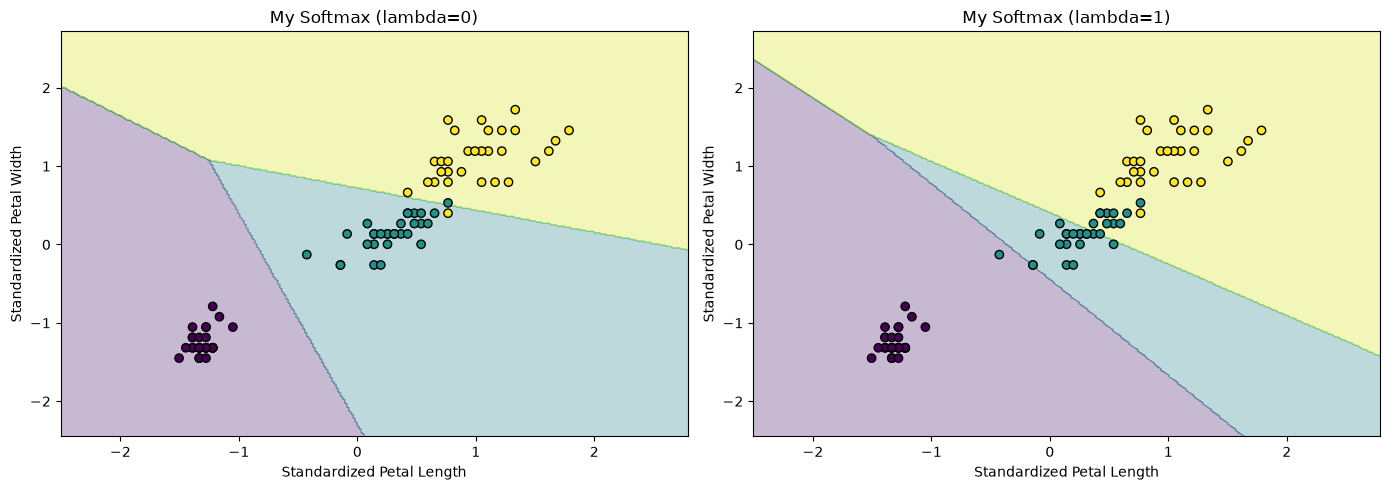

In [689]:
## Plotting Boundaries
def predict_softmax_grid(grid, W):
    grid_bias = add_bias(grid)
    scores = grid_bias @ W
    probabilities = softmax(scores)
    predictions = np.argmax(probabilities, axis=1)
    return predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lam in zip(axes, iris_lambdas):
    W = iris_results[lam]["W"]
    x_min, x_max = X_iris_train_std[:, 0].min() - 1, X_iris_train_std[:, 0].max() + 1
    y_min, y_max = X_iris_train_std[:, 1].min() - 1, X_iris_train_std[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = predict_softmax_grid(grid, W)
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(
        X_iris_train_std[:, 0],
        X_iris_train_std[:, 1],
        c=y_iris_train,
        edgecolors="black",
        cmap="viridis"
    )
    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")
    ax.set_title(f"My Softmax (lambda={lam})")

plt.tight_layout()
plt.show()

* λ = 0 (left): The model has no regularization. Its training accuracy is 97.78%, and validation accuracy is 93.33%.



* λ = 1 (right): Regularization penalizes large weights. The decision boundaries change, and the model has lower training and validation accuracy (86.67% and 83.33%).

In [690]:
from sklearn.linear_model import LogisticRegression
iris_sklearn_results = {}
C_values = {
    0: 1e12,
    1: 1 / len(y_iris_train)
}
for lam, C in C_values.items():
    model = LogisticRegression(
        C=C,
        max_iter=10000
    )
    model.fit(X_iris_train_std, y_iris_train)
    iris_sklearn_results[lam] = model
    print(f"\nLambda = {lam}, C = {C}")
    print("Training accuracy:", model.score(X_iris_train_std, y_iris_train))
    print("Validation accuracy:", model.score(X_iris_val_std, y_iris_val))


Lambda = 0, C = 1000000000000.0
Training accuracy: 0.9777777777777777
Validation accuracy: 0.9333333333333333

Lambda = 1, C = 0.011111111111111112
Training accuracy: 0.8666666666666667
Validation accuracy: 0.8333333333333334


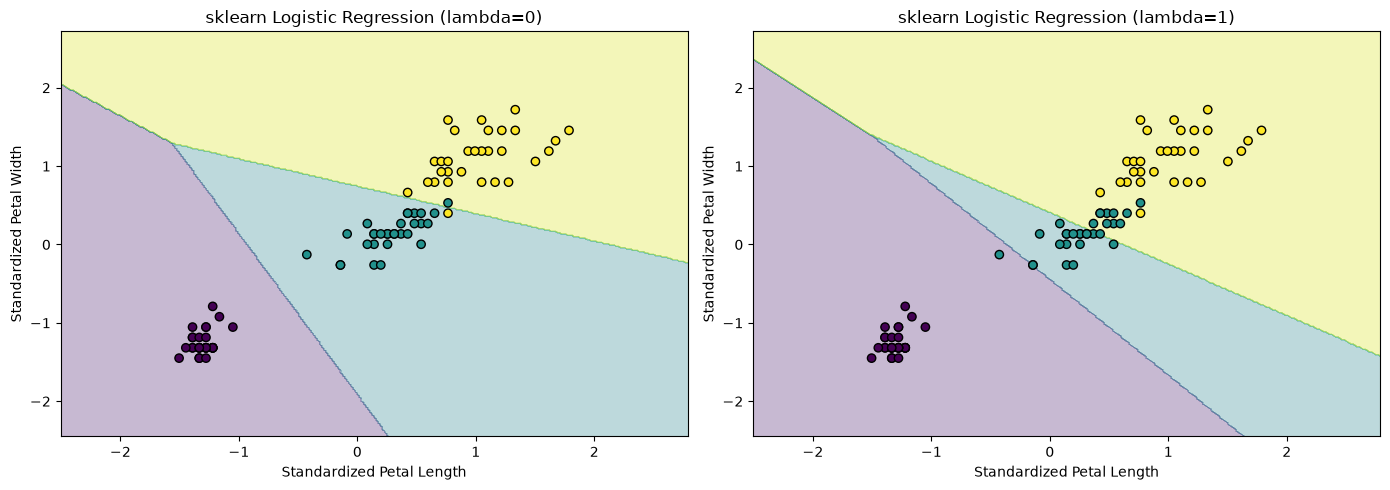

In [691]:
## Plotting sklearn model Boundaries

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lam in zip(axes, iris_lambdas):
    model = iris_sklearn_results[lam]
    x_min, x_max = X_iris_train_std[:, 0].min() - 1, X_iris_train_std[:, 0].max() + 1
    y_min, y_max = X_iris_train_std[:, 1].min() - 1, X_iris_train_std[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(
        X_iris_train_std[:, 0],
        X_iris_train_std[:, 1],
        c=y_iris_train,
        edgecolors="black",
        cmap="viridis"
    )
    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")
    ax.set_title(f"sklearn Logistic Regression (lambda={lam})")
plt.tight_layout()
plt.show()

* The scikit-learn's LogisticRegression model's training and validation accuracies matched those of the Softmax implementation for both regularization settings.

* The decision-region plots from both implementations are very similar. Increasing λ changes the decision boundaries, showing how regularization affects the model's predictions and decision regions.